

# TALLER 3 - Agrupamiento K-Means y Jerárquico Aglomerativo

<br>

**Autores**

Carlos Caicedo  
Salomón Ävila



## Carga y limpieza

In [142]:
pip install ucimlrepo

### Carga

El conjunto de datos original se encontraba previamente depurado y sin registros faltantes ni valores atípicos, estructurado a partir de dos esquemas de estandarización: las variables psicométricas (escalas NEO-FFI-R, BIS-11 e ImpSS) fueron normalizadas mediante *Z-score* ($\mu = 0, \sigma \approx 1$), mientras que las variables sociodemográficas ordinales y categóricas (edad, género, nivel educativo, país y etnia) fueron cuantificadas en valores continuos normalizados mediante escalamiento óptimo (*Optimal Scaling* / *CatPCA*).

In [143]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
drug_consumption_quantified = fetch_ucirepo(id=373)

# data (as pandas dataframes)
X = drug_consumption_quantified.data.features
y = drug_consumption_quantified.data.targets

### Diccionario para desnormalización

Se construyó el diccionario maestro `MAPPINGS_UCI` y se desarrollaron las funciones reutilizables `denormalize_uci_value` y `denormalize_series`, con el propósito de recuperar las categorías originales de las cinco variables sociodemográficas (`age`, `gender`, `education`, `country` y `ethnicity`) a partir de sus valores estandarizados, utilizando coincidencia exacta o distancia mínima.

In [144]:
import numpy as np
import pandas as pd

# Diccionario maestro con los mapeos oficiales del UCI Drug Consumption Dataset
MAPPINGS_UCI = {
    'age': {
        -0.95197: '18-24',
        -0.07854: '25-34',
        0.49788: '35-44',
        1.09449: '45-54',
        1.82213: '55-64',
        2.59171: '65+',
    },
    'gender': {-0.48246: 'Masculino', 0.48246: 'Femenino'},
    'education': {
        -2.43591: 'Menor a 16 años',
        -1.73791: 'Terminó a los 16 años',
        -1.43719: 'Terminó a los 17 años',
        -1.22751: 'Terminó a los 18 años',
        -0.61113: 'Algún curso universitario (sin título)',
        -0.05921: 'Certificado / Diploma técnico profesional',
        0.45468: 'Grado universitario / Pregrado',
        1.16365: 'Maestría',
        1.98437: 'Doctorado',
    },
    'country': {
        -0.09765: 'Australia',
        0.24923: 'Canadá',
        -0.46841: 'Nueva Zelanda',
        -0.28595: 'Otros',
        0.96082: 'Reino Unido',
        -0.57009: 'Estados Unidos',
        -0.28595: 'República de Irlanda',
    },
    'ethnicity': {
        -0.50212: 'Asiático',
        -1.10702: 'Negro',
        1.90725: 'Blanco y Negro',
        0.12600: 'Blanco y Asiático',
        -0.22166: 'Otros',
        -0.31685: 'Blanco',
        0.11440: 'Otros',
    },
}


def denormalize_uci_value(
    value, variable_name: str, return_closest: bool = True
):
    """Desnormaliza un valor (o un promedio continuo) mapeándolo a la categoría original

    del dataset UCI Drug Consumption.

    Parámetros:
    -----------
    value : float o int
        El valor numérico normalizado (ej. -0.34766 o un promedio de clúster).
    variable_name : str
        Nombre de la variable ('age', 'gender', 'education', 'country',
        'ethnicity').
    return_closest : bool, default True
        Si es True, busca la categoría con la menor distancia euclidiana al valor
        dado
        (ideal para desnormalizar medias/promedios continuos).
        Si es False, busca el match exacto con tolerancia.

    Retorna:
    --------
    str: La etiqueta textual legible de la categoría correspondiente.
    """
    col = variable_name.lower()
    if col not in MAPPINGS_UCI:
        raise ValueError(
            f"Variable '{variable_name}' no disponible. Opciones válidas: {list(MAPPINGS_UCI.keys())}"
        )

    mapping = MAPPINGS_UCI[col]
    keys = np.array(list(mapping.keys()))

    if return_closest:
        # Encuentra la clave más cercana numéricamente (mínima diferencia absoluta)
        idx_closest = np.argmin(np.abs(keys - value))
        closest_key = keys[idx_closest]
        return mapping[closest_key]
    else:
        # Match exacto con margen de tolerancia por coma flotante
        for k, label in mapping.items():
            if np.isclose(value, k, atol=1e-3):
                return label
        return 'Desconocido'


def denormalize_series(series: pd.Series, variable_name: str) -> pd.Series:
    return series.apply(
        lambda x: denormalize_uci_value(
            x, variable_name, return_closest=False
        )
    )

In [145]:
import pandas as pd

# Combinar características (X) y objetivos (y) en un solo DataFrame
df = pd.concat([X, y], axis=1)

# Mostrar las primeras filas del DataFrame
df.head()

,age,gender,education,country,ethnicity,nscore,escore,oscore,ascore,cscore,...,ecstasy,heroin,ketamine,legalh,lsd,meth,mushrooms,nicotine,semer,vsa
0,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,-0.00665,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,-0.14277,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,-1.01450,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
3,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,0.58489,...,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
4,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,1.30612,...,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0


### Binarizar consumo o no consumo

Se recodificaron las 19 variables de consumo de sustancias de su escala original de siete niveles (`CL0` a `CL6`) a una codificación binaria, asignando `0` a los no consumidores (`CL0`) y `1` a quienes registraron algún consumo histórico (`CL1` a `CL6`). Asimismo, se corrigió el error tipográfico en el nombre de la variable `'impuslive'`, renombrándola como `'impulsive'`.

| Code | Meaning | Description |
| --- | --- | --- |
| CL0 | Never Used | The person has never tried the substance |
| CL1 | Used over a Decade Ago | Last used more than ten years ago |
| CL2 | Used in Last Decade | Last used within the last ten years |
| CL3 | Used in Last Year | Last used within the last year |
| CL4 | Used in Last Month | Last used within the last month |
| CL5 | Used in Last Week | Last used within the last week |
| CL6 | Used in Last Day | Last used within the last day |

In [146]:
import numpy as np
cols = ['alcohol', 'amphet', 'amyl', 'benzos', 'caff', 'cannabis','choc', 'coke', 'crack', 'ecstasy', 'heroin', 'ketamine','legalh', 'lsd', 'meth', 'mushrooms', 'nicotine', 'semer', 'vsa']
df01 = df.copy()

# Binarizar consumo
for c in cols:
    df01[c] = np.where(df01[c] == 'CL0', 0, 1)

# Corregir el error de dedo en el nombre de la columna 'impuslive'
if 'impuslive' in df01.columns:
    df01 = df01.rename(columns={'impuslive': 'impulsive'})
    print("Columna 'impuslive' corregida a 'impulsive'")

Columna 'impuslive' corregida a 'impulsive'


### Distribución Original de los Datos

La reducción de dimensionalidad mediante el Análisis de Componentes Principales (PCA) permite observar una única nube de puntos densa y concentrada en la región central del gráfico, pero no se evidencia separaciones claras, agrupaciones o clústeres que se formen de manera natural.

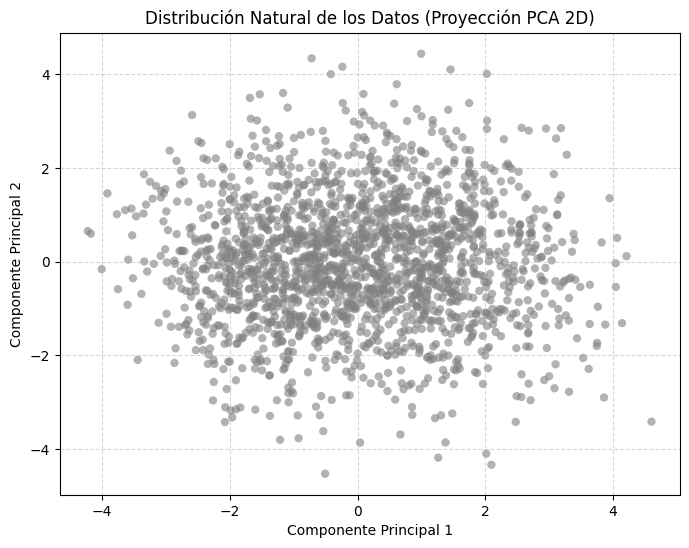

In [147]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reducción a 2D usando PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c='gray', alpha=0.6, edgecolors='none')
plt.title('Distribución Natural de los Datos (Proyección PCA 2D)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Distribución por sustancia

Se proyectaron los individuos en el espacio PCA 2D, diferenciando visualmente consumidores y no consumidores de cada sustancia. Los resultados muestran una superposición considerable entre ambos grupos, indicando que el consumo se distribuye entre distintos perfiles y que la proyección lineal en dos dimensiones no permite establecer una separación visual clara.

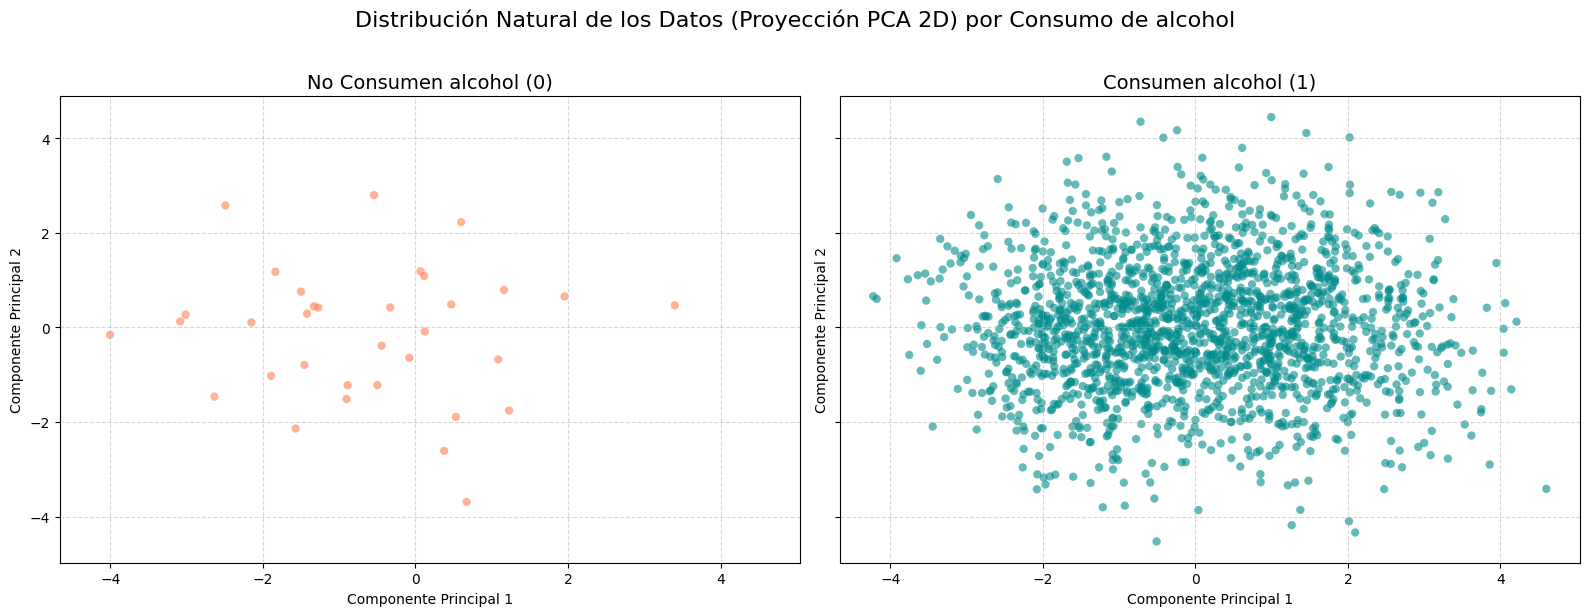

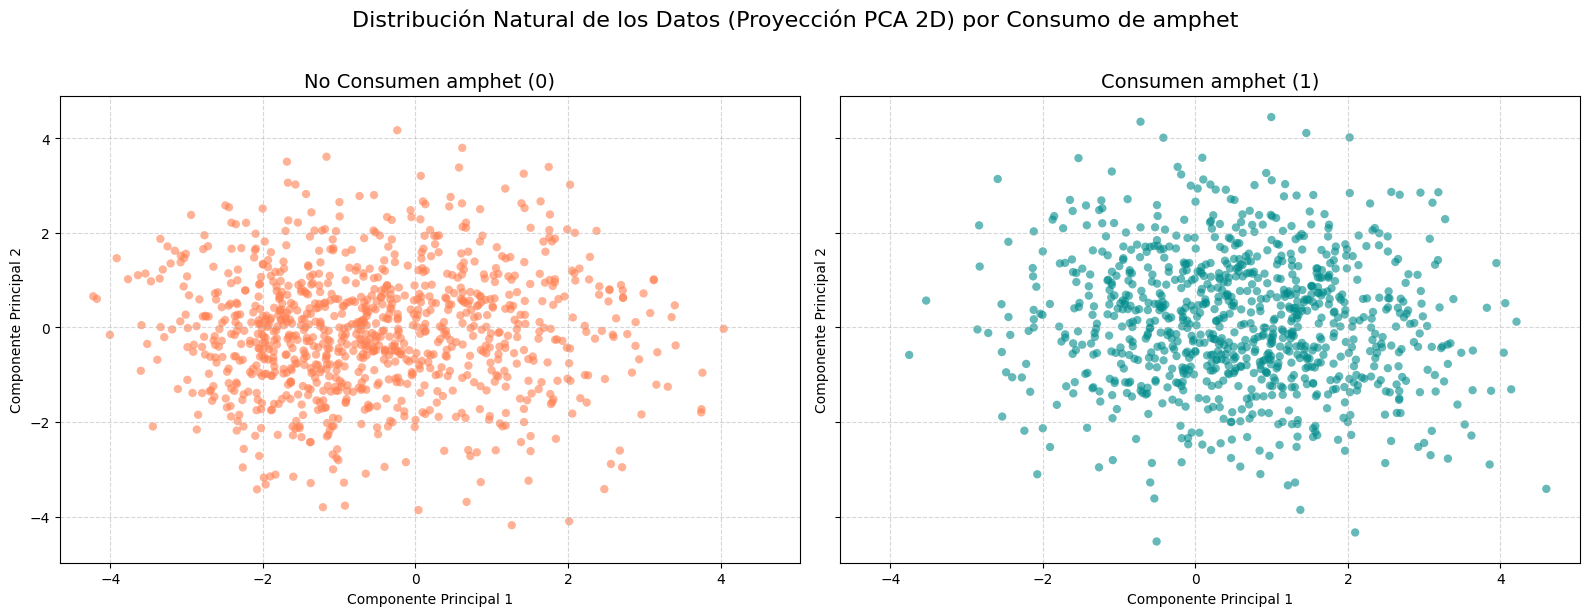

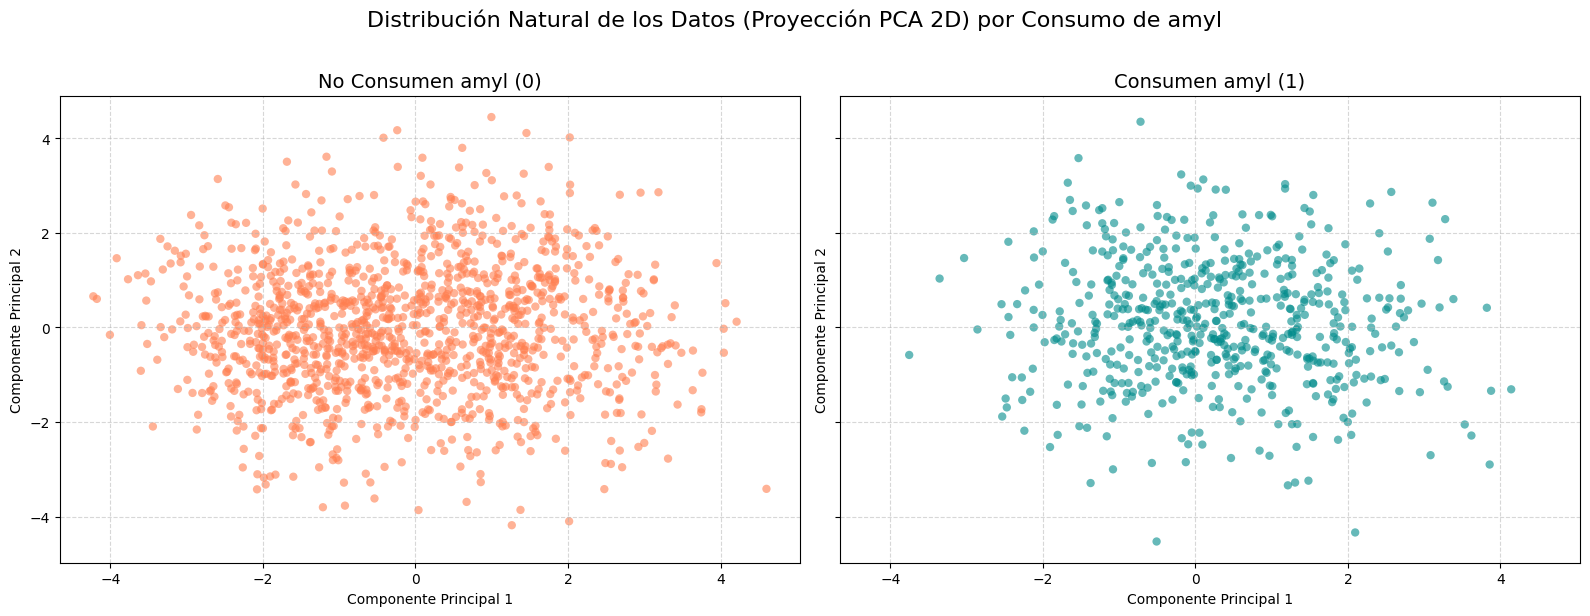

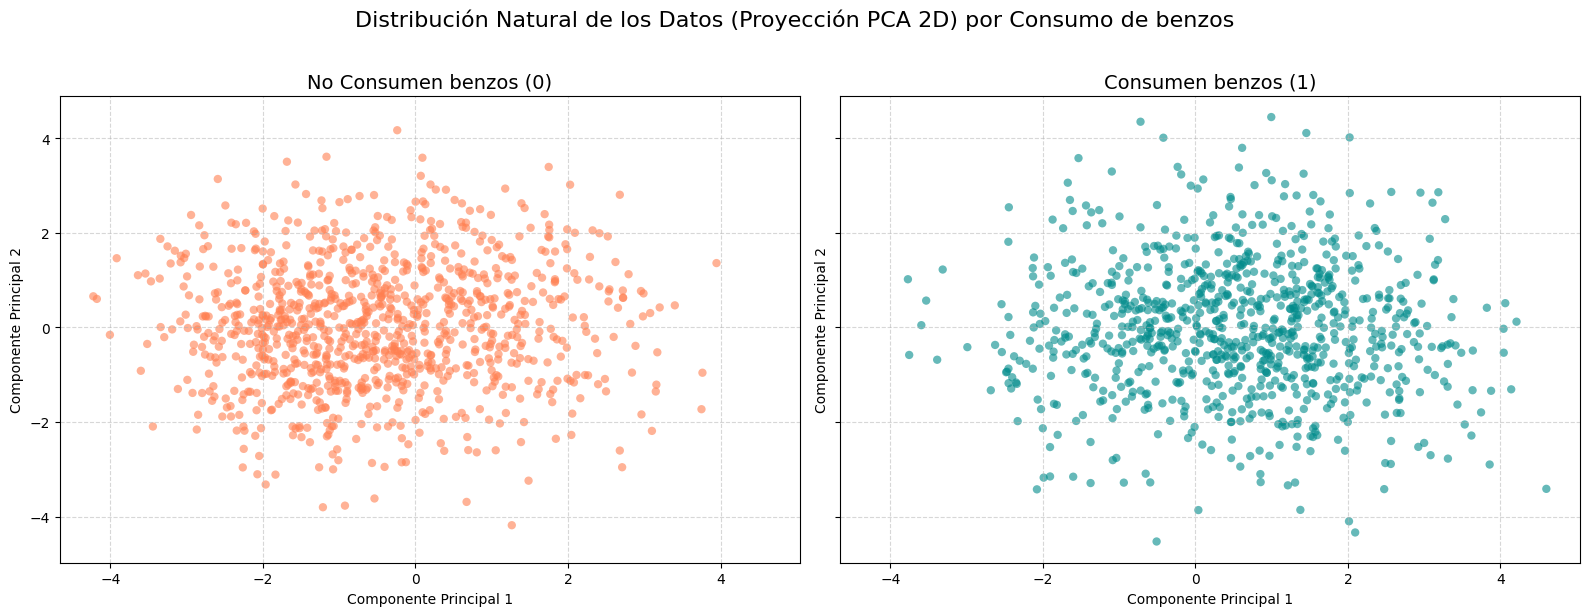

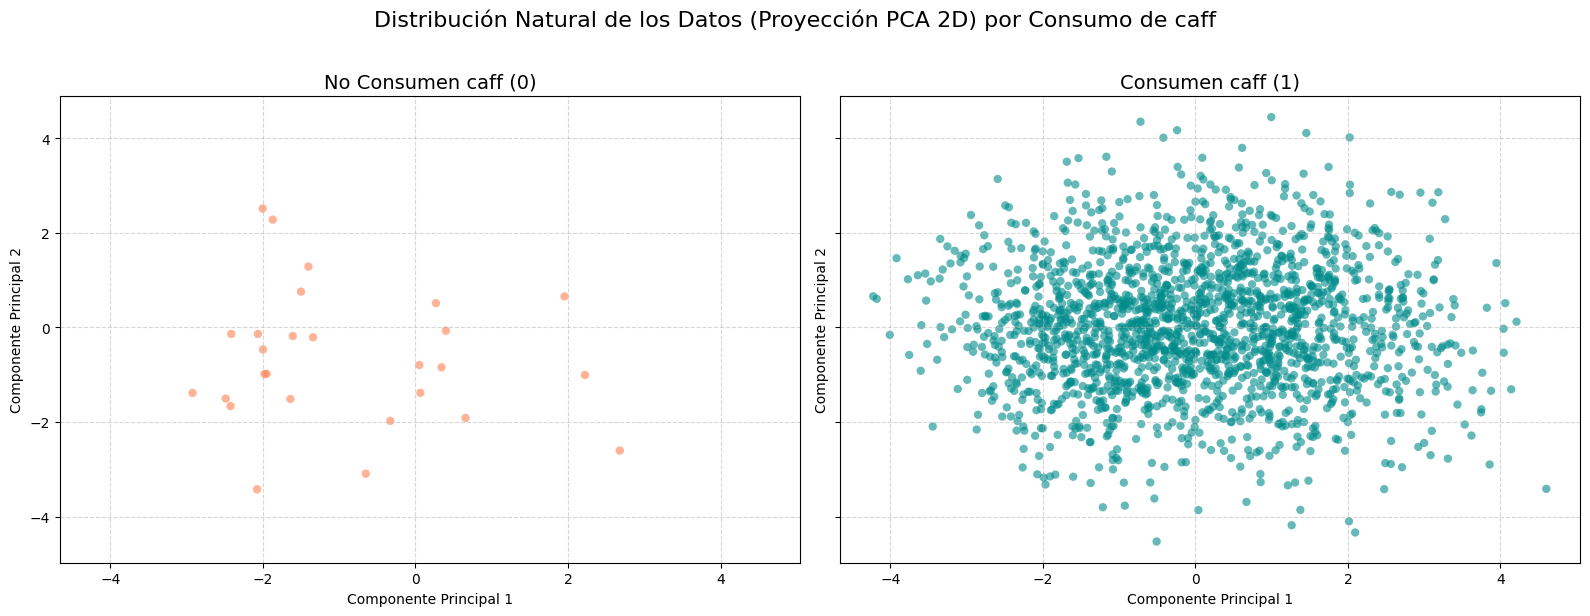

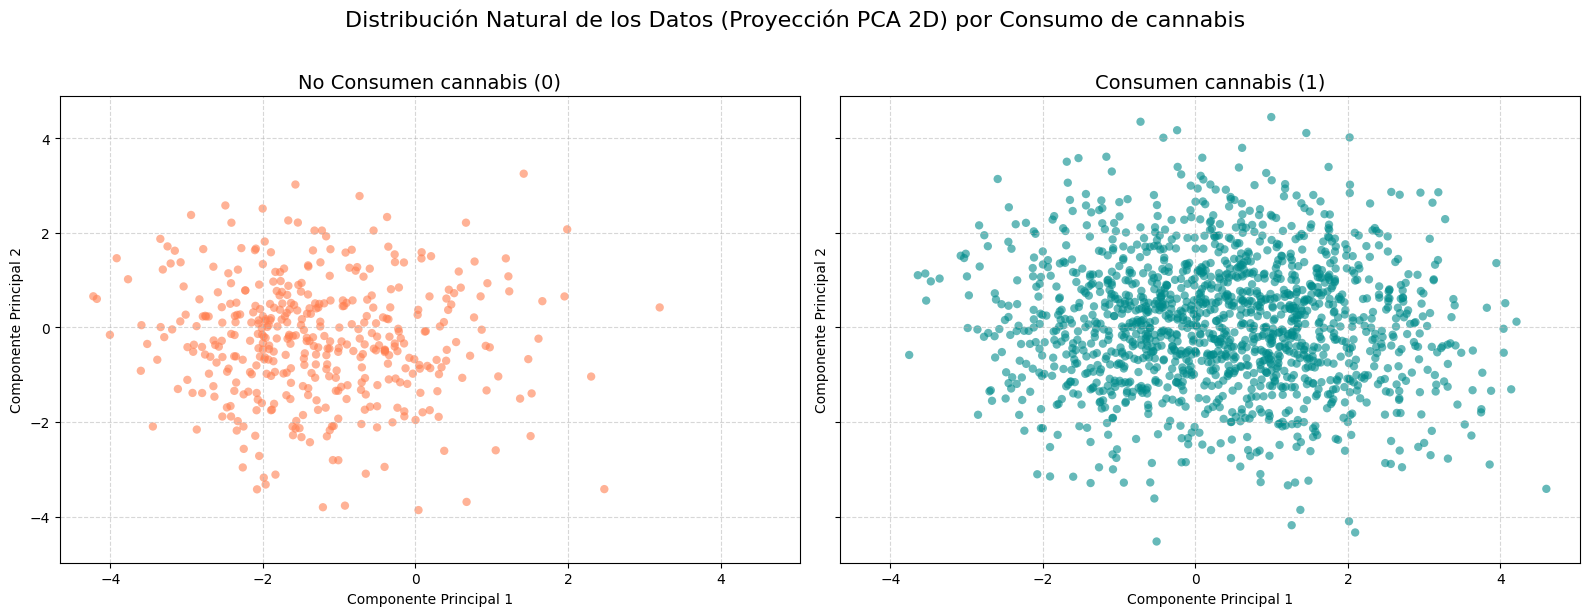

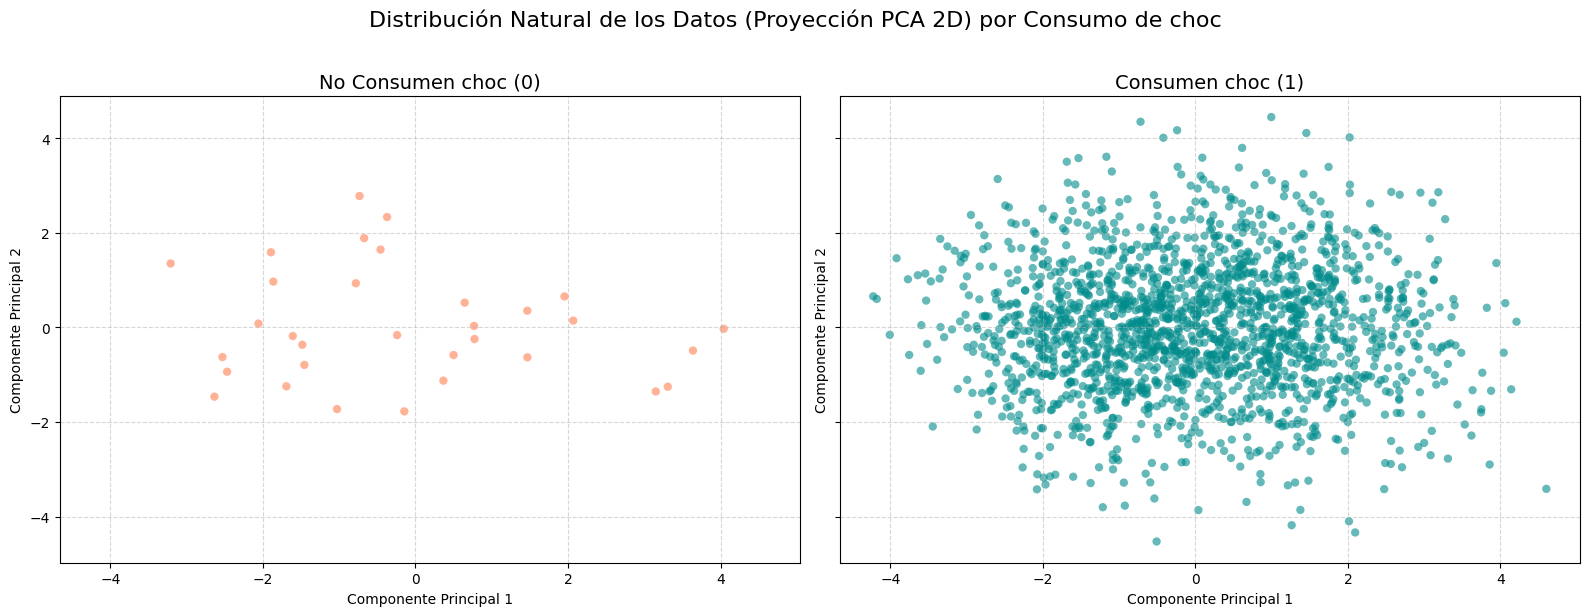

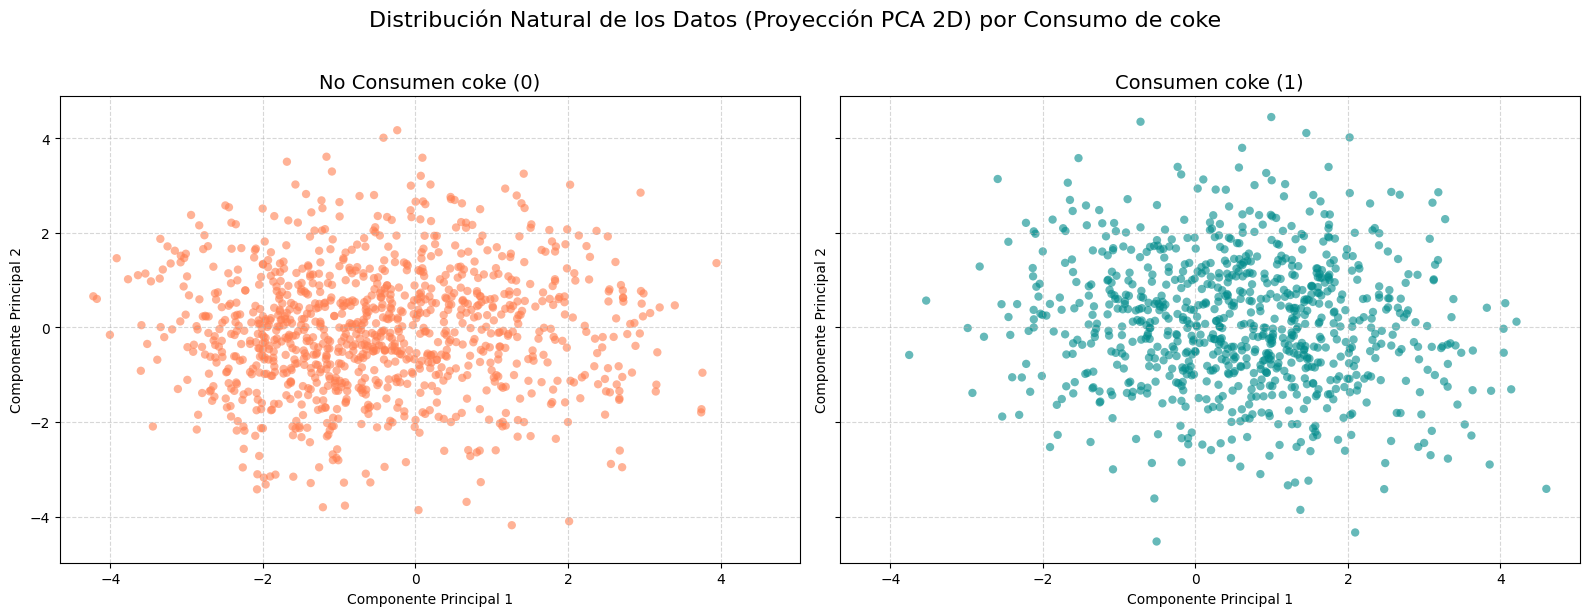

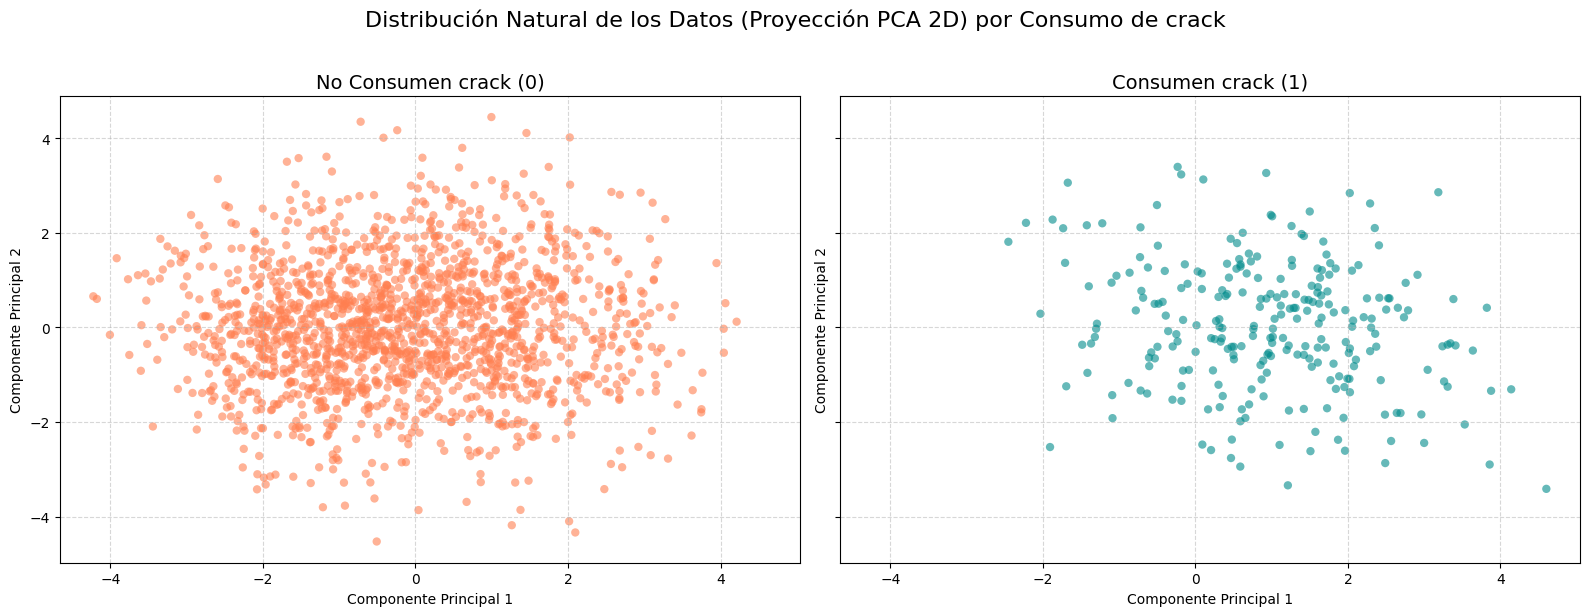

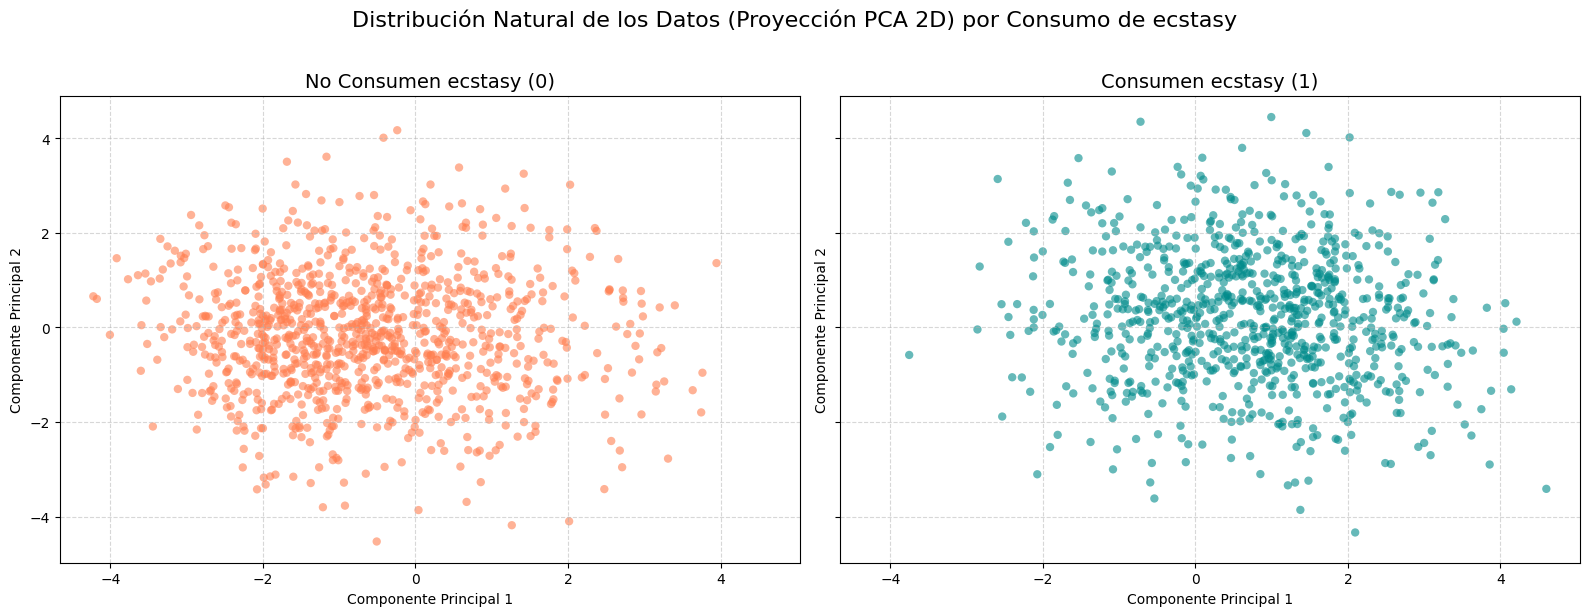

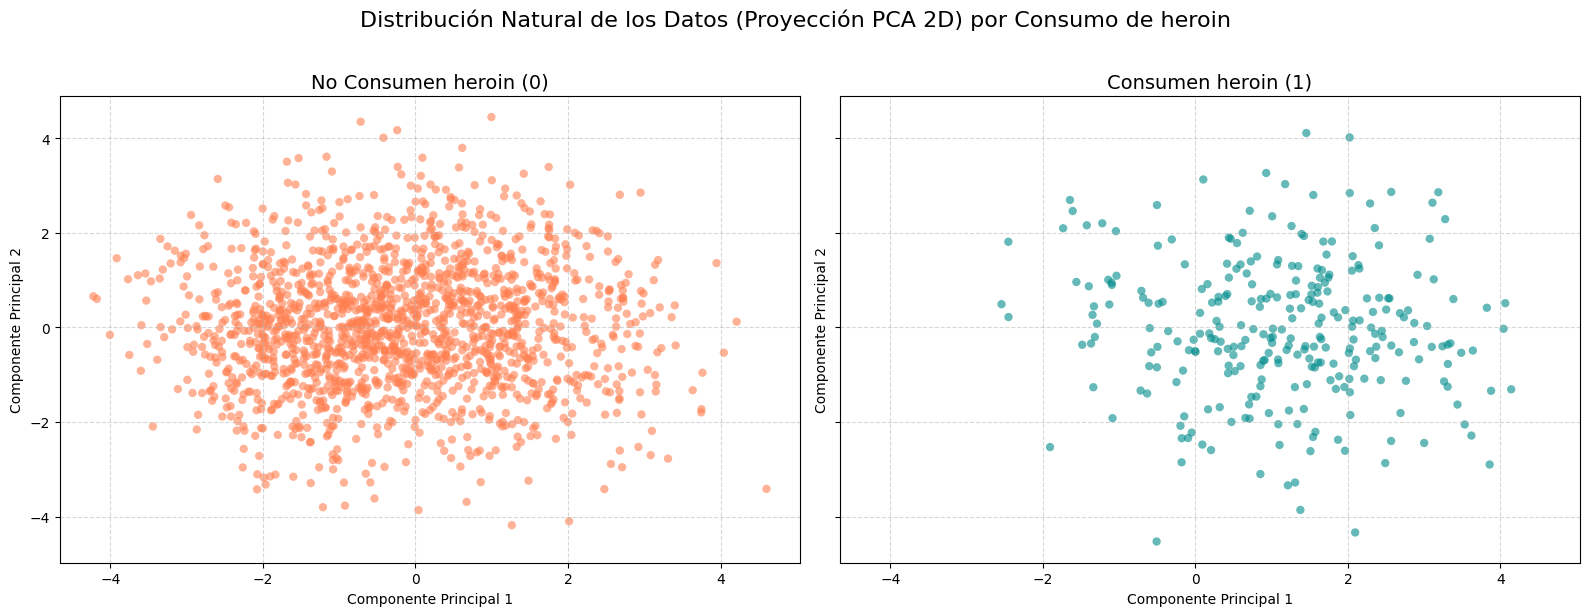

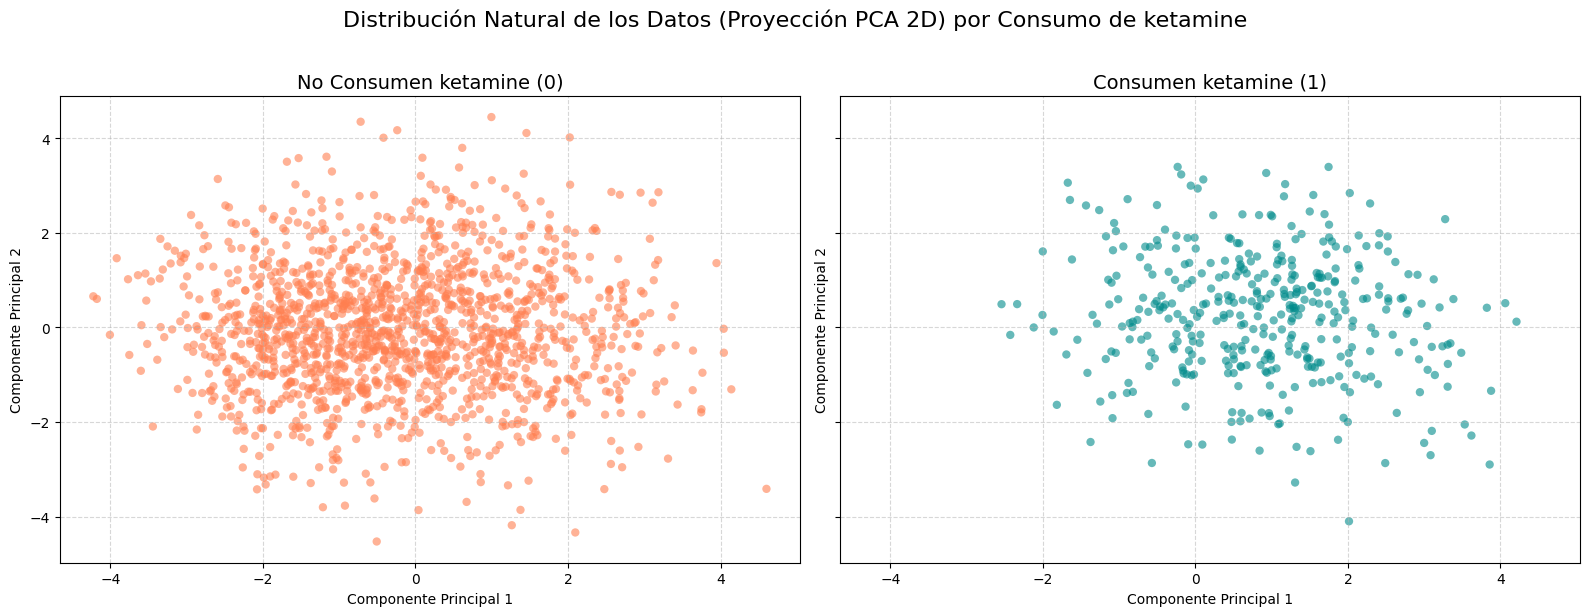

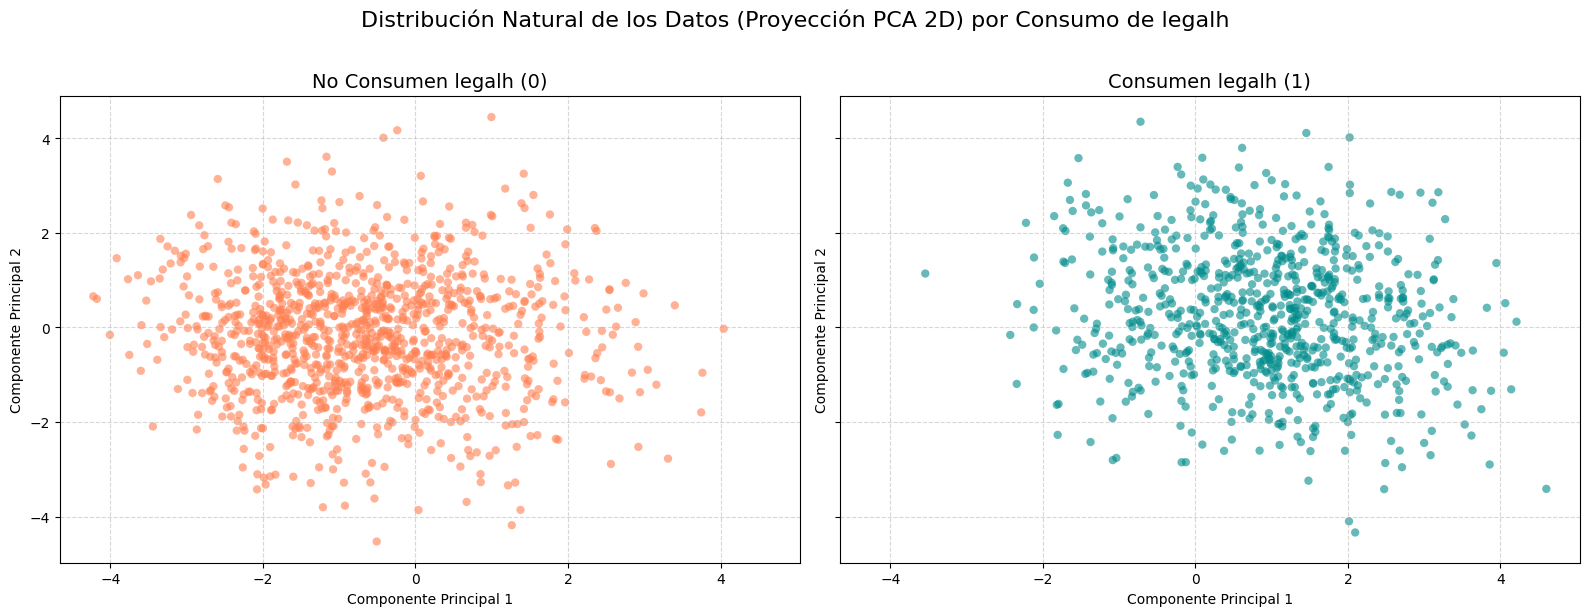

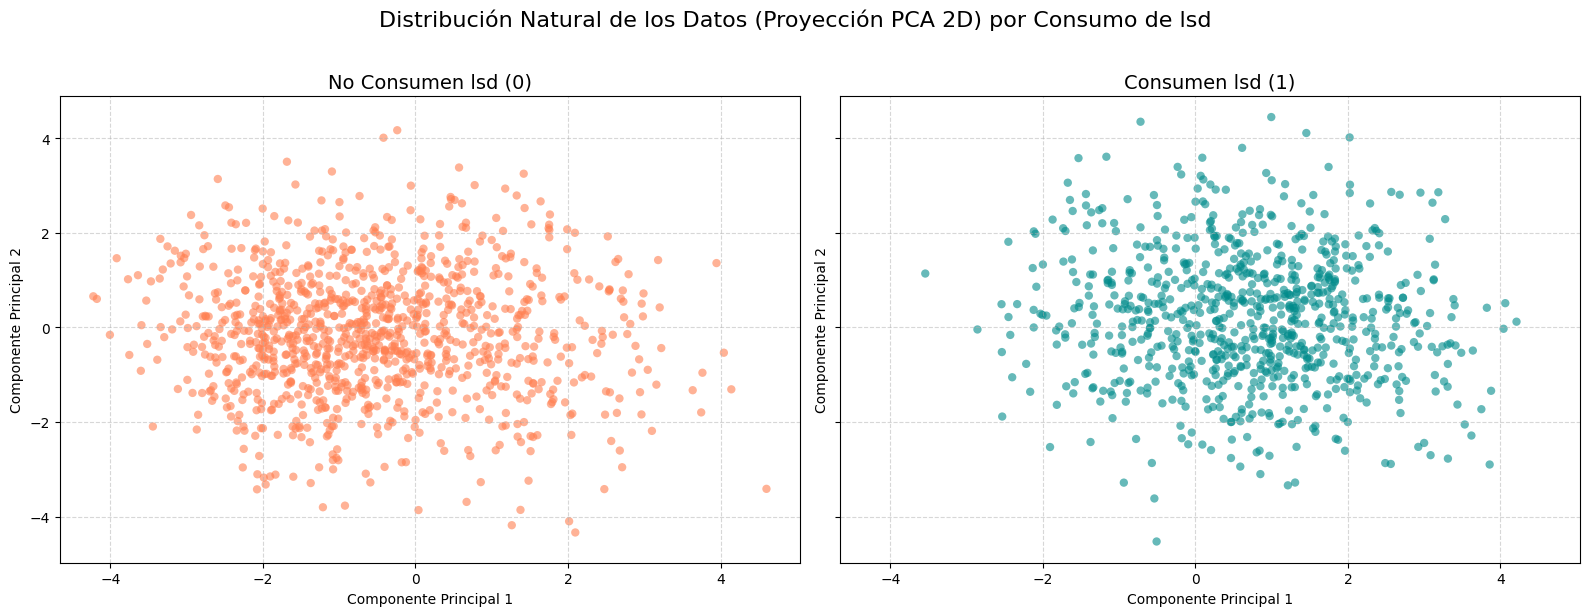

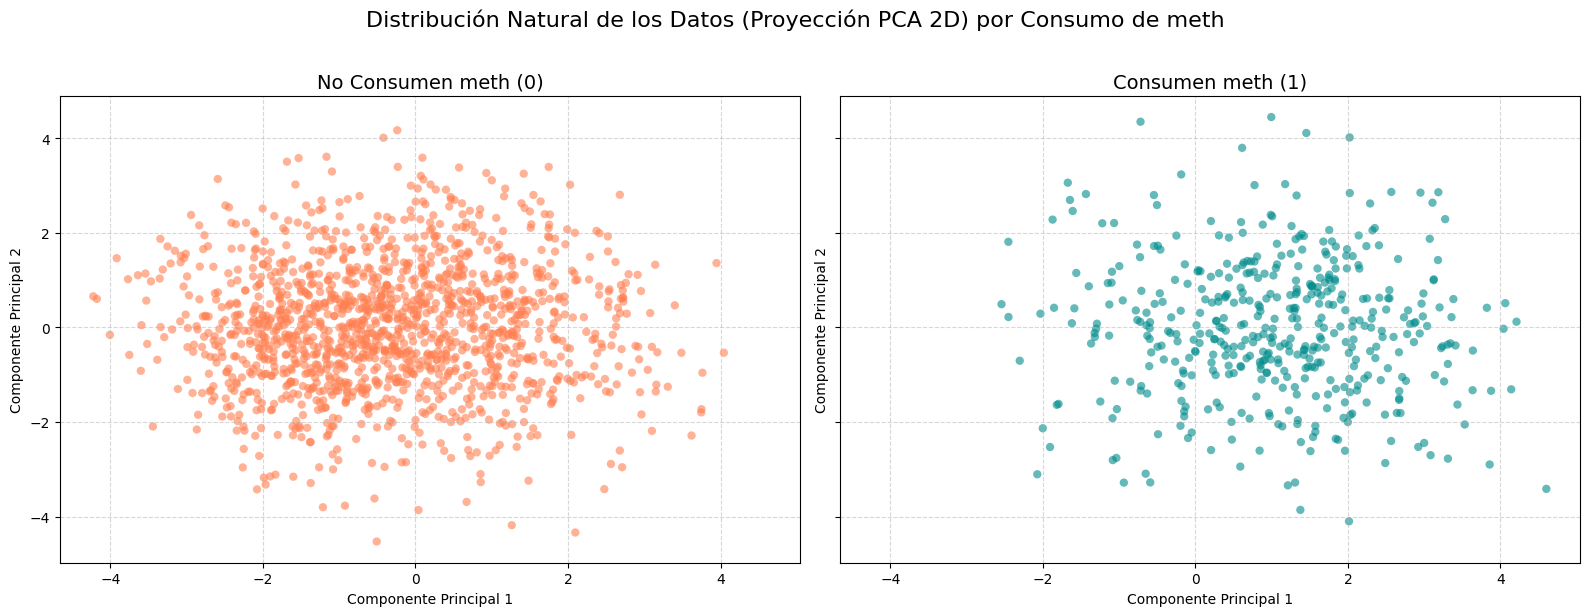

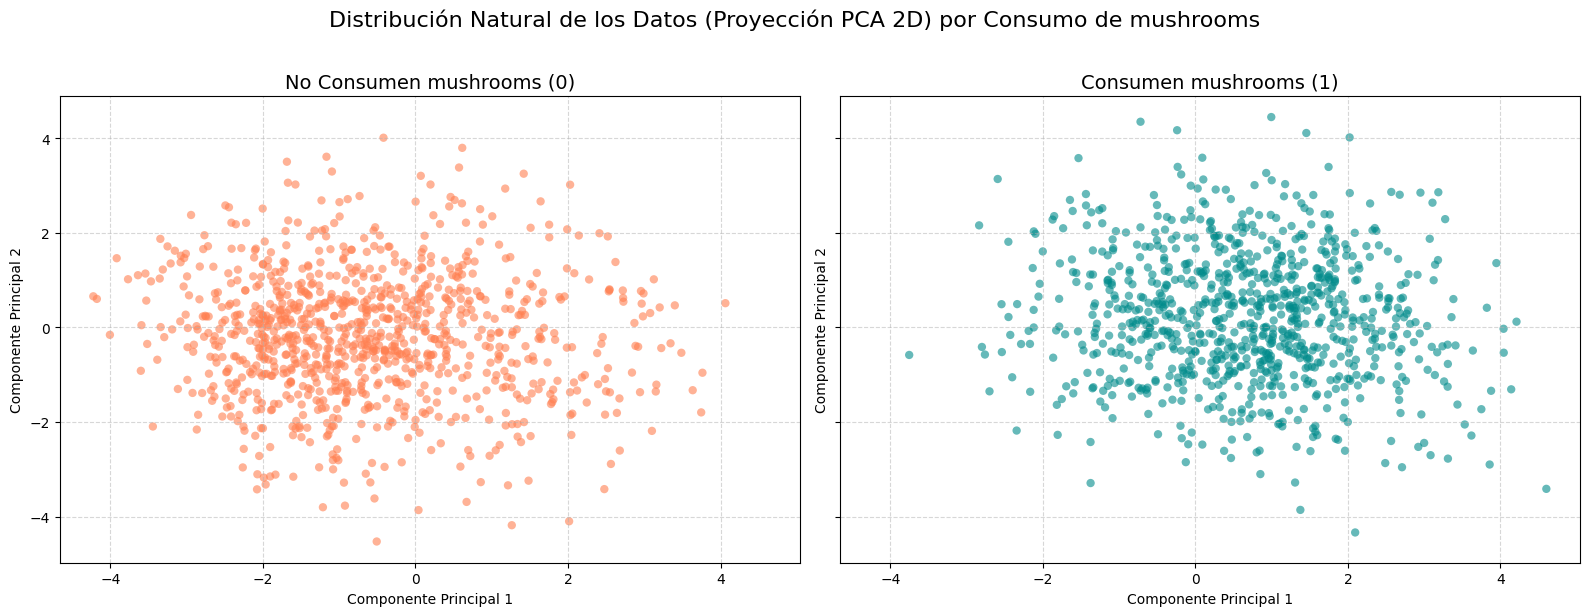

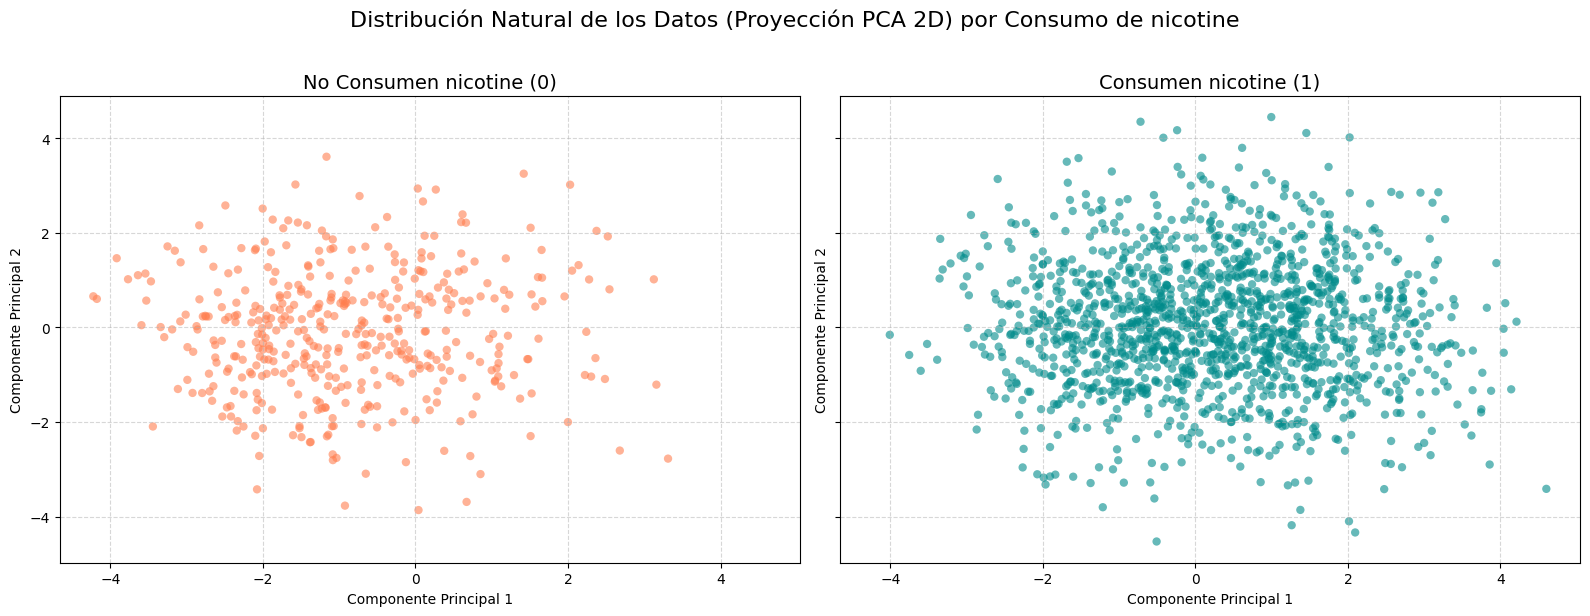

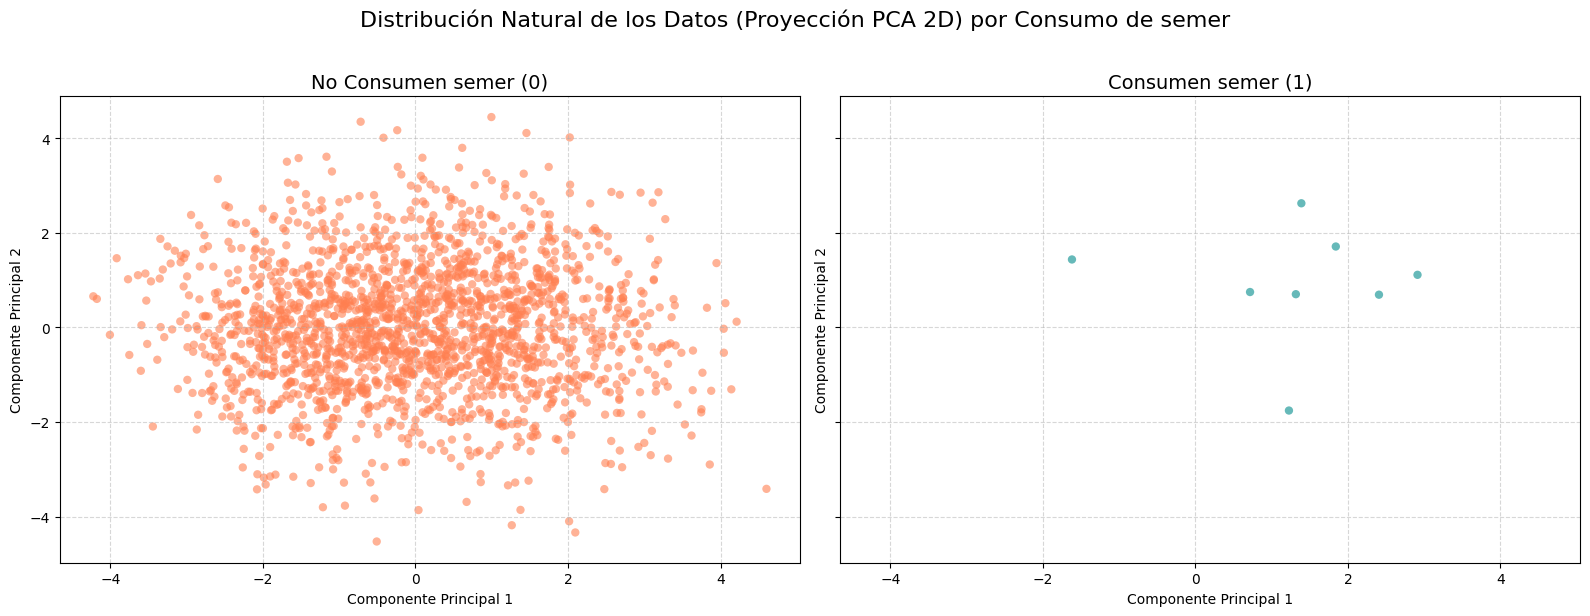

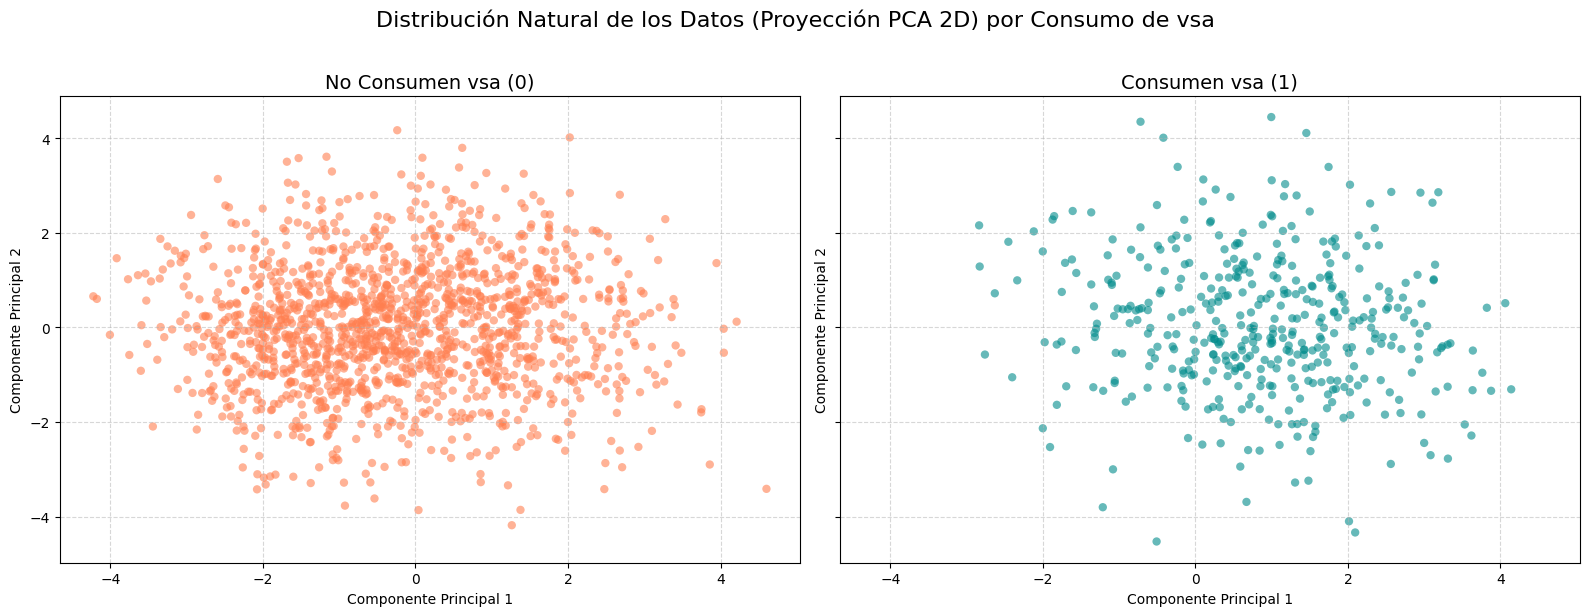

In [148]:
import matplotlib.pyplot as plt

for c in cols:
  # Crear subplots para los datos originales (sin clústeres) segmentados por consumo de c
  fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

  # Filtrar datos para No Consumidores de c (0) y Consumidores (1)
  # Corregido usando f-strings para evitar conflictos de comillas y hacer dinámico el nombre
  for ax, consume_c, title in zip(axes, [0, 1], [f'No Consumen {c} (0)', f'Consumen {c} (1)']):
      mask = df01[c] == consume_c

      # Graficar la distribución natural en color gris o azul neutro
      ax.scatter(
          X_pca[mask, 0],
          X_pca[mask, 1],
          c='darkcyan' if consume_c == 1 else 'coral',
          alpha=0.6,
          edgecolors='none'
      )

      ax.set_title(title, fontsize=14)
      ax.set_xlabel('Componente Principal 1')
      ax.set_ylabel('Componente Principal 2')
      ax.grid(True, linestyle='--', alpha=0.5)

  plt.suptitle(f'Distribución Natural de los Datos (Proyección PCA 2D) por Consumo de {c}', fontsize=16, y=1.02)
  plt.tight_layout()
  plt.show()

## K-MEANS

 Las características demográficas y de personalidad en 'X' ya están en formato numérico y estandarizadas de origen en el dataset.

### Método del codo

Se calcularon la inercia y el coeficiente de silueta para determinar el número óptimo de clústeres. Los resultados indican que K=2 presenta el mayor coeficiente de silueta entre las alternativas evaluadas, por lo que constituye la mejor partición según este indicador.

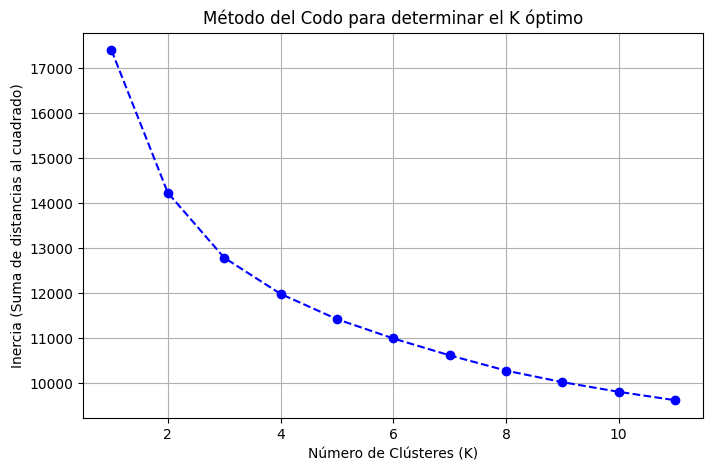

In [149]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X_kmeans = X.copy()

inertia = []
k_range = range(1, 12)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_kmeans)
    inertia.append(kmeans.inertia_)

# Graficar el Método del Codo
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='b')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('Inercia (Suma de distancias al cuadrado)')
plt.title('Método del Codo para determinar el K óptimo')
plt.grid(True)
plt.show()



### Identificar el mejor K

Se evaluó el coeficiente de silueta para distintas particiones de clústeres (K=2, 3 y 4) buscando maximizar la cohesión y separación de los grupos. Los resultados indican que K=2 es la partición matemáticamente óptima al obtener el puntaje más alto (0.1663), superando a K=3 (0.1423) y K=4 (0.1099), lo que confirma la tendencia visual sugerida por el método del codo.


In [150]:
from sklearn.metrics import silhouette_score

for k_val in [2, 3, 4]:
  kmeans_test = KMeans(n_clusters=k_val, random_state=42, n_init=10)
  labels_test = kmeans_test.fit_predict(X_kmeans)
  score = silhouette_score(X_kmeans, labels_test)
  print(f"Para K = {k_val}, el Coeficiente de Silueta es: {score:.4f}")

Para K = 2, el Coeficiente de Silueta es: 0.1663
Para K = 3, el Coeficiente de Silueta es: 0.1423
Para K = 4, el Coeficiente de Silueta es: 0.1099


In [151]:
k_optimo = 2
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df01['cluster'] = kmeans_final.fit_predict(X_kmeans)

print(f"Se ha ejecutado K-Means con K={k_optimo}.")
print(df01['cluster'].value_counts())

Se ha ejecutado K-Means con K=2.
cluster
0    955
1    930
Name: count, dtype: int64


### Agrupación usando K-Means (K=2)

Se aplicó el algoritmo K-Means con K=2, obteniendo dos grupos de tamaños similares: 955 y 930 personas. La partición divide la nube central de datos en dos segmentos, mostrando una distribución equilibrada de la población entre ambos clústeres.

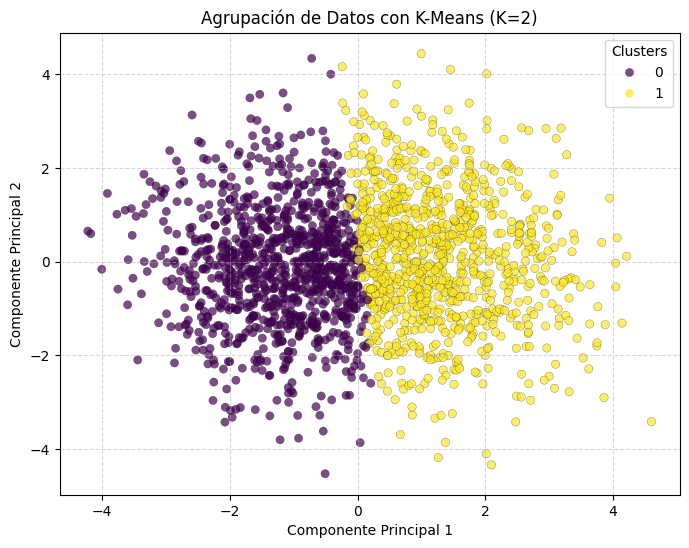

In [152]:
plt.figure(figsize=(8, 6))
scatter_km = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df01['cluster'], cmap='viridis', alpha=0.7, edgecolors='k', linewidths=0.2)
plt.title('Agrupación de Datos con K-Means (K=2)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(*scatter_km.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Caracterización Psicométrica y Sociodemográfica de los Clústeres

Se caracterizaron los dos clústeres según sus variables sociodemográficas y psicométricas, identificando diferencias entre ambos perfiles. El Clúster 1 concentra principalmente jóvenes de 18 a 24 años, con mayor presencia masculina, impulsividad y búsqueda de sensaciones elevadas. Por su parte, el Clúster 0 agrupa principalmente personas mayores de 25 años, con mayor presencia femenina y puntuaciones más altas en calma y responsabilidad, y menores niveles de impulsividad.

/tmp/ipykernel_569/3842366174.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster', y=var, data=df01, ax=axes[i], palette='Set2')
/tmp/ipykernel_569/3842366174.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster', y=var, data=df01, ax=axes[i], palette='Set2')
/tmp/ipykernel_569/3842366174.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster', y=var, data=df01, ax=axes[i], palette='Set2')
/tmp/ipykernel_569/3842366174.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be

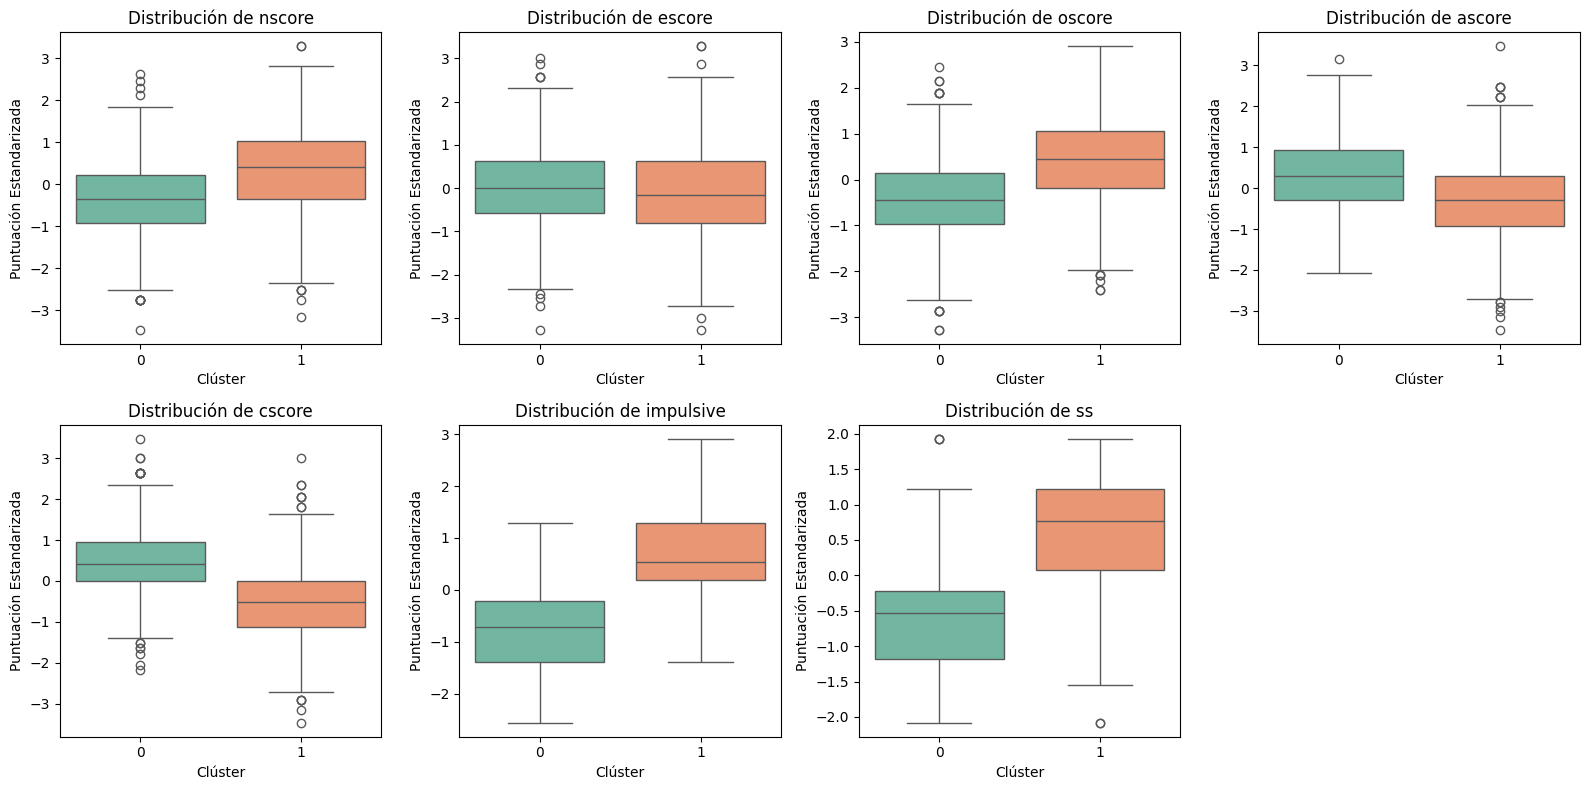

In [153]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de las variables psicológicas a analizar
variables_psicologicas = [
    'nscore', 'escore', 'oscore', 'ascore',
    'cscore', 'impulsive', 'ss'
]

# Crear una figura y una cuadrícula de subgráficos (2 filas x 4 columnas)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))

# Aplanar la matriz de ejes para iterar fácilmente
axes = axes.flatten()

# Iterar sobre cada variable y crear su respectivo boxplot
for i, var in enumerate(variables_psicologicas):
    sns.boxplot(x='cluster', y=var, data=df01, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Distribución de {var}')
    axes[i].set_xlabel('Clúster')
    axes[i].set_ylabel('Puntuación Estandarizada')

# Ocultamos el 8vo gráfico vacío
axes[7].set_visible(False)

plt.tight_layout()
plt.show()

### perfil promedio

Se observa que el Clúster 0 representa a un perfil femenino de 35-44 años con educación universitaria (alta responsabilidad: 0.49), mientras que el Clúster 1 define a un perfil masculino más joven (25-34 años) con formación técnica, destacando por su alta impulsividad (0.58) y búsqueda de sensaciones (0.61).


In [174]:
perfil_clusters = df01.groupby('cluster')[
    [
        'age',
        'gender',
        'education',
        'nscore',
        'escore',
        'oscore',
        'ascore',
        'cscore',
        'impulsive',
        'ss',
    ]
].mean()

# Desnormalizar las columnas sociodemográficas del perfil promedio para K-Means
for col in ['age', 'gender', 'education']:
    perfil_clusters[col] = perfil_clusters[col].apply(lambda val: denormalize_uci_value(val, col))

print(perfil_clusters)

           age     gender                                  education  \
cluster                                                                
0        35-44   Femenino             Grado universitario / Pregrado   
1        25-34  Masculino  Certificado / Diploma técnico profesional   

           nscore    escore    oscore    ascore    cscore  impulsive        ss  
cluster                                                                         
0       -0.327222  0.066442 -0.395183  0.309443  0.495233  -0.553519 -0.602176  
1        0.336113 -0.068559  0.404723 -0.318258 -0.509328   0.583025  0.611692  


### Perfil y Distribución Sociodemográfica de los Clústeres

Se generaron tabulaciones cruzadas normalizadas. Se observa: el Clúster 1 concentra mayoritariamente a la población joven (53.55% tiene entre 18 y 24 años) y masculina (64.30%), mientras que el Clúster 0 tiene una distribución de edad más madura y balanceada (25.13% entre 35-44 años) con predominancia femenina (63.87%).

In [155]:
# 1. Crear una copia de trabajo para no alterar el DataFrame original (df01)
df02 = df01.copy()

# 2. Lista de variables sociodemográficas a desnormalizar
vars_demograficas = ['age', 'gender', 'education', 'country', 'ethnicity']

# 3. Aplicar la desnormalización sobre la copia df02
for col in vars_demograficas:
  if col in df02.columns:
    df02[col] = denormalize_series(df02[col], col)

# 4. Generar y mostrar la tabulación cruzada en porcentaje para cada variable
for col in vars_demograficas:
  if col in df02.columns:
    print(f'=== Distribución porcentual de {col.upper()} por Clúster ===')
    tabla_porcentajes = (
        pd.crosstab(df02['cluster'], df02[col], normalize='index') * 100
    )
    print(tabla_porcentajes.round(2))
    print('\n')

=== Distribución porcentual de AGE por Clúster ===
age      18-24  25-34  35-44  45-54  55-64   65+
cluster                                         
0        15.18  26.49  25.13  23.56   7.85  1.78
1        53.55  24.52  12.47   7.42   1.94  0.11


=== Distribución porcentual de GENDER por Clúster ===
gender   Femenino  Masculino
cluster                     
0           63.87      36.13
1           35.70      64.30


=== Distribución porcentual de EDUCATION por Clúster ===
education  Algún curso universitario (sin título)  \
cluster                                             
0                                           11.31   
1                                           42.80   

education  Certificado / Diploma técnico profesional  Doctorado  \
cluster                                                           
0                                              17.28       7.23   
1                                              11.29       2.15   

education  Grado universitario / Pregrad

### Tabulaciones cruzadas

Se realizaron tabulaciones cruzadas y pruebas de Chi-cuadrado para evaluar las diferencias en los patrones de consumo entre ambos clústeres. Los resultados muestran una mayor concentración de consumo de sustancias como cannabis, éxtasis, LSD y hongos en el Clúster 1. Las pruebas estadísticas evidencian que estas diferencias son estadísticamente significativas, descartando que se deban únicamente al azar.

In [156]:
# Lista de sustancias a evaluar (usamos las columnas binarizadas que definimos previamente)
sustancias_cols = cols

# DataFrame auxiliar con la asignación del clúster y las variables de consumo ya binarizadas
df_consumo = df01[sustancias_cols + ['cluster']].copy()

# Proporción (porcentaje) de consumidores por clúster
prevalencia_consumo = (
    df_consumo.groupby('cluster')[sustancias_cols].mean() * 100
).round(2)
print(prevalencia_consumo.T)  # Transpuesto para ver sustancias en las filas

cluster        0      1
alcohol    97.80  98.60
amphet     32.15  64.73
amyl       27.12  34.52
benzos     31.83  62.47
caff       97.91  99.25
cannabis   62.62  93.98
choc       98.01  98.60
coke       29.63  60.65
crack       6.39  21.18
ecstasy    26.70  65.48
heroin      6.28  23.66
ketamine   10.99  31.18
legalh     18.85  65.70
lsd        24.82  62.26
meth       10.89  37.85
mushrooms  28.80  67.53
nicotine   67.23  87.63
semer       0.10   0.75
vsa        11.73  34.19


### Pruebas de hipótesis

Se aplicaron pruebas estadísticas Chi-cuadrado para evaluar las diferencias de consumo entre los clústeres. Los resultados muestran diferencias altamente significativas en sustancias como Legal highs, Éxtasis, Hongos, Cannabis y LSD (p \< 0.001). En cambio, el consumo de Alcohol, Chocolate y la sustancia de control Semer no presenta diferencias estadísticamente significativas (p \> 0.05).

In [157]:
from scipy.stats import chi2_contingency

resultados_hipotesis = []

for droga in sustancias_cols:
  # Crear la tabla de contingencia de frecuencias absolutas
  contingency_table = pd.crosstab(df_consumo['cluster'], df_consumo[droga])

  # Ejecutar prueba Chi-cuadrado
  chi2, p_val, dof, _ = chi2_contingency(contingency_table)

  resultados_hipotesis.append({
      'Sustancia': droga,
      'Chi2': round(chi2, 3),
      'p-value': round(p_val, 5),
      '(p < 0.05)': 'Sí' if p_val < 0.05 else 'No',
  })

df_hipotesis = pd.DataFrame(resultados_hipotesis).sort_values(
    by='Chi2', ascending=False
)
print(df_hipotesis.to_string(index=False))

Sustancia    Chi2  p-value (p < 0.05)
   legalh 422.734  0.00000         Sí
  ecstasy 283.887  0.00000         Sí
mushrooms 281.666  0.00000         Sí
 cannabis 269.009  0.00000         Sí
      lsd 267.526  0.00000         Sí
   amphet 199.056  0.00000         Sí
     meth 185.266  0.00000         Sí
     coke 181.882  0.00000         Sí
   benzos 176.375  0.00000         Sí
      vsa 133.782  0.00000         Sí
 ketamine 114.716  0.00000         Sí
   heroin 111.071  0.00000         Sí
 nicotine 110.668  0.00000         Sí
    crack  86.058  0.00000         Sí
     amyl  11.753  0.00061         Sí
     caff   5.094  0.02401         Sí
    semer   3.273  0.07041         No
  alcohol   1.285  0.25699         No
     choc   0.666  0.41457         No


## Método Jerárquico

Utilizamos 'X_kmeans' que contiene las características predictoras ya estandarizadas numéricamente de origen.

### Dendograma

Se aplicó el clustering jerárquico mediante el análisis de distancias, representado a través de un dendrograma. Los resultados muestran una ramificación principal en dos grandes grupos, cuya distribución en el espacio PCA presenta una separación visual similar a la obtenida mediante K-Means.

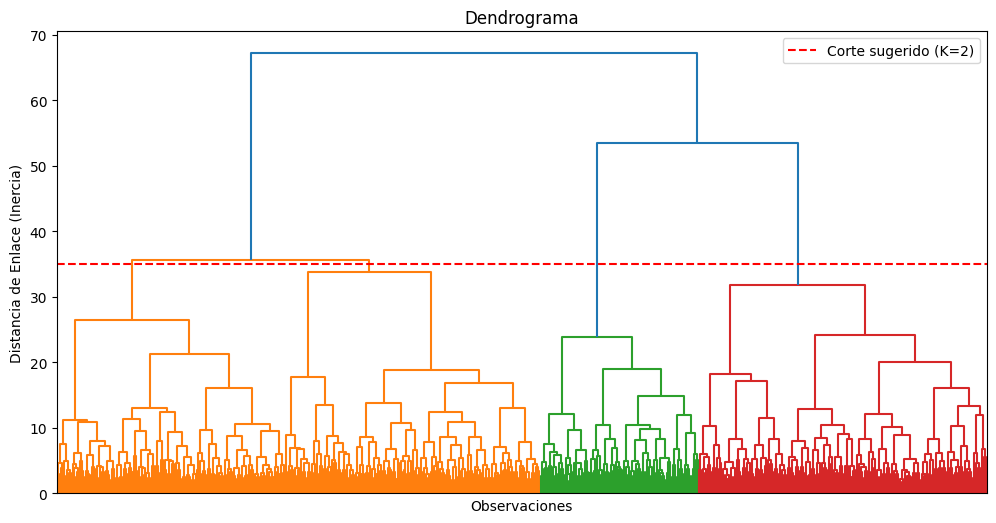

In [158]:
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

X_hierarchical = X_kmeans.copy()

# Construcción del Dendrograma estándar
plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(X_hierarchical, method='ward'), no_labels=True)
plt.title('Dendrograma')
plt.xlabel('Observaciones')
plt.ylabel('Distancia de Enlace (Inercia)')
plt.axhline(y=35, color='r', linestyle='--', label='Corte sugerido (K=2)')
plt.legend()
plt.show()



### Agrupación usando Clustering Jerárquico

Se observa que el límite de decisión difiere claramente del generado por K-Means: mientras K-Means realiza un corte vertical y lineal, el método jerárquico crea una partición diagonal con un notable solapamiento en el centro de la distribución, reflejando una agrupación basada en proximidad progresiva de vecinos y no en centroides globales.

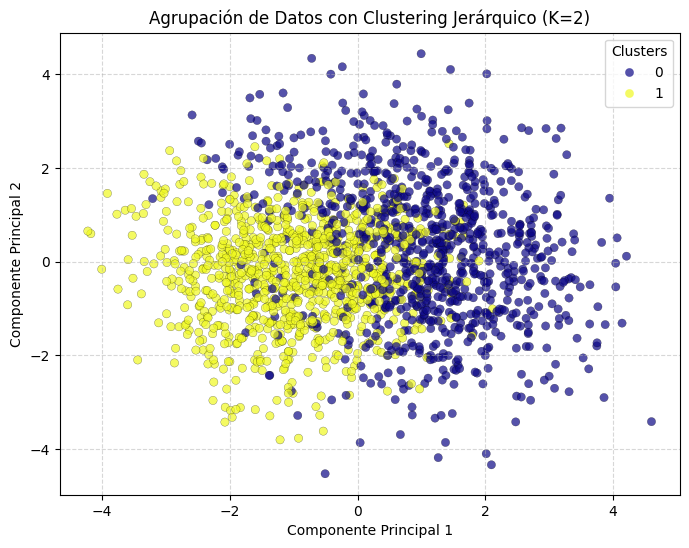

In [159]:
from sklearn.cluster import AgglomerativeClustering

# 1. Ejecutar el Clustering Jerárquico para obtener las etiquetas faltantes
hc_final = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
df01['cluster_jerarquico'] = hc_final.fit_predict(X_kmeans)

# 2. Generar la gráfica con los clusters calculados
plt.figure(figsize=(8, 6))
scatter_hc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df01['cluster_jerarquico'], cmap='plasma', alpha=0.7, edgecolors='k', linewidths=0.2)
plt.title('Agrupación de Datos con Clustering Jerárquico (K=2)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(*scatter_hc.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Caracterización Psicométrica y Sociodemográfica de los Clústeres

Se graficó la distribución de los rasgos de personalidad para los grupos del modelo jerárquico mediante diagramas de caja. Se observa que el modelo separó a la población capturando un Clúster 0 caracterizado por valores atípicamente altos de impulsividad y búsqueda de sensaciones ('ss'), frente a un Clúster 1 que concentra los niveles más altos de responsabilidad ('cscore') y los más bajos de neurosis ('nscore').

/tmp/ipykernel_569/2056402598.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster_jerarquico', y=var, data=df01, ax=axes[i], palette='Set2')
/tmp/ipykernel_569/2056402598.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster_jerarquico', y=var, data=df01, ax=axes[i], palette='Set2')
/tmp/ipykernel_569/2056402598.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster_jerarquico', y=var, data=df01, ax=axes[i], palette='Set2')
/tmp/ipykernel_569/2056402598.py:18: FutureWarning: 

Passing `palette` without assignin

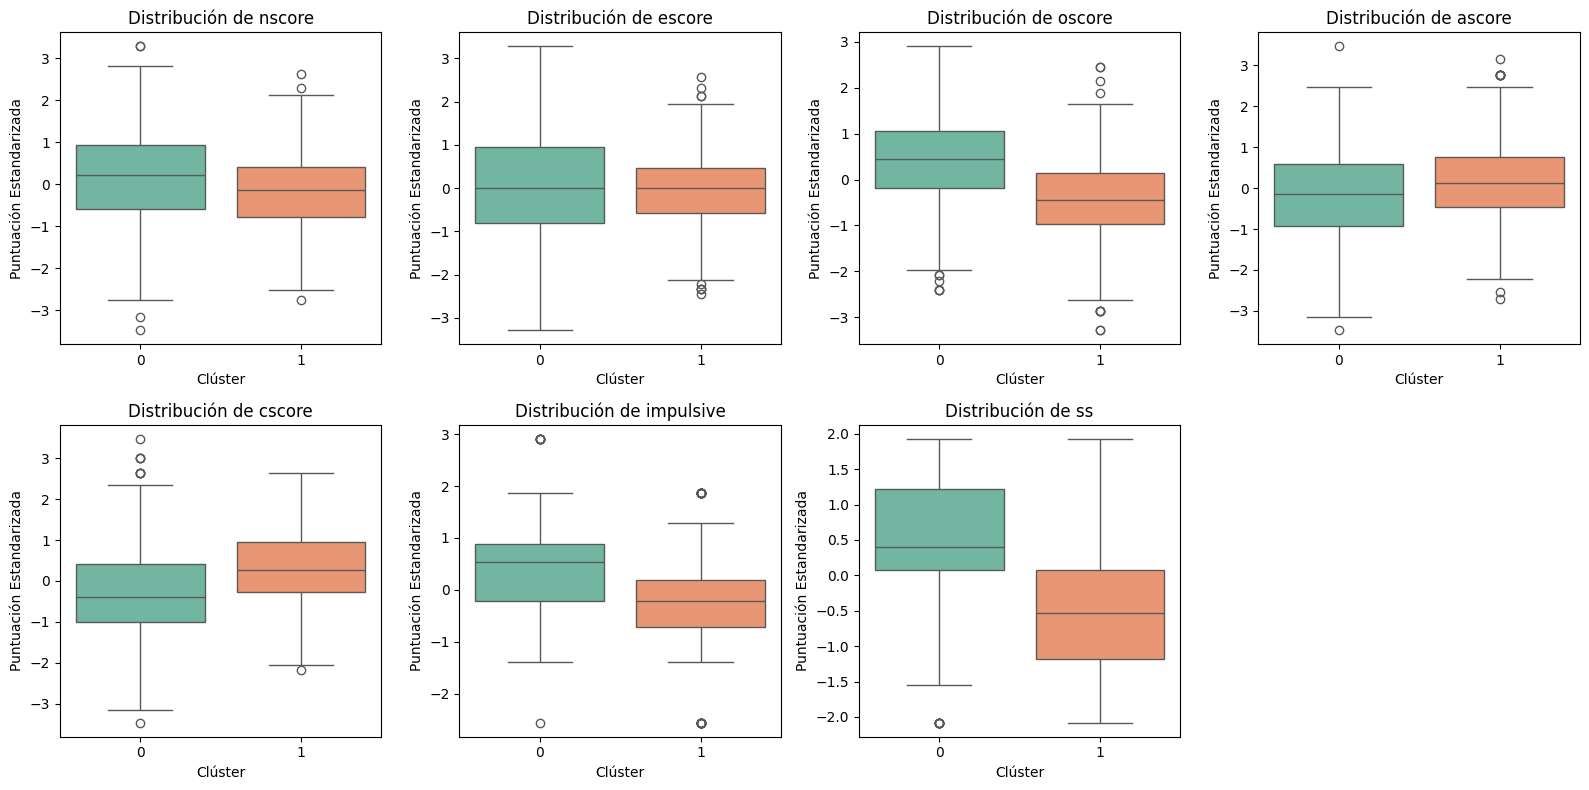

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de las variables psicológicas a analizar
variables_psicologicas = [
    'nscore', 'escore', 'oscore', 'ascore',
    'cscore', 'impulsive', 'ss'
]

# Crear una figura y una cuadrícula de subgráficos (2 filas x 4 columnas)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))

# Aplanar la matriz de ejes para iterar fácilmente
axes = axes.flatten()

# Iterar sobre cada variable y crear su respectivo boxplot
for i, var in enumerate(variables_psicologicas):
    sns.boxplot(x='cluster_jerarquico', y=var, data=df01, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Distribución de {var}')
    axes[i].set_xlabel('Clúster')
    axes[i].set_ylabel('Puntuación Estandarizada')

# Ocultamos el 8vo gráfico vacío
axes[7].set_visible(False)

plt.tight_layout()
plt.show()

### perfil promedio

Se evidencia que el Clúster 0 promedia un hombre de 25-34 años con educación técnica (impulsividad media de 0.40), mientras que el Clúster 1 perfila a una mujer de 35-44 años con grado universitario (responsabilidad media de 0.27), coincidiendo con K-Means.

In [175]:
perfil_clusters_jerarquico = df01.groupby('cluster_jerarquico')[
    [
        'age',
        'gender',
        'education',
        'nscore',
        'escore',
        'oscore',
        'ascore',
        'cscore',
        'impulsive',
        'ss',
    ]
].mean()

# Desnormalizar las columnas sociodemográficas del perfil promedio para Clustering Jerárquico
for col in ['age', 'gender', 'education']:
    perfil_clusters_jerarquico[col] = perfil_clusters_jerarquico[col].apply(lambda val: denormalize_uci_value(val, col))

print(perfil_clusters_jerarquico)

                      age     gender  \
cluster_jerarquico                     
0                   25-34  Masculino   
1                   35-44   Femenino   

                                                    education    nscore  \
cluster_jerarquico                                                        
0                   Certificado / Diploma técnico profesional  0.205244   
1                              Grado universitario / Pregrado -0.189045   

                      escore    oscore    ascore    cscore  impulsive  \
cluster_jerarquico                                                      
0                   0.020798  0.447510 -0.174780 -0.304123   0.406461   
1                  -0.019479 -0.413411  0.160591  0.279510  -0.360692   

                          ss  
cluster_jerarquico            
0                   0.490823  
1                  -0.458623  


### Perfil y Distribución Sociodemográfica de los Clústeres

Los datos revelan que el Clúster 0 agrupa masivamente al segmento juvenil (61.17% son de 18-24 años) y a estudiantes sin título universitario (46.57%), a diferencia del Clúster 1 que presenta una fuerte concentración en el Reino Unido (81.45%) y perfiles educativos completos (grados y maestrías).

In [162]:
# 1. Crear una copia de trabajo para no alterar el DataFrame original (df01)
df02 = df01.copy()

# 2. Lista de variables sociodemográficas a desnormalizar
vars_demograficas = ['age', 'gender', 'education', 'country', 'ethnicity']

# 3. Aplicar la desnormalización sobre la copia df02
for col in vars_demograficas:
  if col in df02.columns:
    df02[col] = denormalize_series(df02[col], col)

# 4. Generar y mostrar la tabulación cruzada en porcentaje para cada variable
for col in vars_demograficas:
  if col in df02.columns:
    print(f'=== Distribución porcentual de {col.upper()} por Clúster ===')
    tabla_porcentajes = (
        pd.crosstab(df02['cluster_jerarquico'], df02[col], normalize='index') * 100
    )
    print(tabla_porcentajes.round(2))
    print('\n')

=== Distribución porcentual de AGE por Clúster ===
age                 18-24  25-34  35-44  45-54  55-64   65+
cluster_jerarquico                                         
0                   61.17  24.00   9.62   4.42   0.77  0.00
1                    9.17  26.91  27.42  25.89   8.77  1.83


=== Distribución porcentual de GENDER por Clúster ===
gender              Femenino  Masculino
cluster_jerarquico                     
0                      37.06      62.94
1                      61.88      38.12


=== Distribución porcentual de EDUCATION por Clúster ===
education           Algún curso universitario (sin título)  \
cluster_jerarquico                                           
0                                                    46.57   
1                                                     8.66   

education           Certificado / Diploma técnico profesional  Doctorado  \
cluster_jerarquico                                                         
0                                

### Tabulaciones cruzadas

Se observa que el Clúster 0 (el grupo joven) ostenta tasas de uso radicalmente mayores en casi todas las sustancias ilícitas, alcanzando un 93.25% de prevalencia para Cannabis y un 64.49% para Éxtasis, superando ampliamente los registros del Clúster 1 (64.12% y 28.64%, respectivamente).

In [163]:
# Lista de sustancias a evaluar (usamos las columnas binarizadas que definimos previamente)
sustancias_cols = cols

# DataFrame auxiliar con la asignación del clúster y las variables de consumo ya binarizadas
df_consumo = df01[sustancias_cols + ['cluster_jerarquico']].copy()

# Proporción (porcentaje) de consumidores por clúster
prevalencia_consumo = (
    df_consumo.groupby('cluster_jerarquico')[sustancias_cols].mean() * 100
).round(2)
print(prevalencia_consumo.T)  # Transpuesto para ver sustancias en las filas

cluster_jerarquico      0      1
alcohol             98.23  98.17
amphet              61.06  36.39
amyl                29.87  31.60
benzos              58.74  36.09
caff                99.34  97.86
cannabis            93.25  64.12
choc                98.23  98.37
coke                56.97  33.84
crack               18.92   8.87
ecstasy             64.49  28.64
heroin              21.68   8.56
ketamine            30.86  11.82
legalh              67.59  18.35
lsd                 59.29  28.54
meth                37.83  11.62
mushrooms           65.71  31.50
nicotine            86.39  68.91
semer                0.77   0.10
vsa                 31.64  14.68


### Pruebas de hipótesis

Se aplicaron pruebas Chi-cuadrado para evaluar las diferencias en los patrones de consumo entre los clústeres del modelo jerárquico. Los resultados muestran una tendencia similar a K-Means, con asociaciones altamente significativas en sustancias como Legal highs (χ²=466.35), Éxtasis (χ²=242.06) y Cannabis (χ²=231.69), todas con p \< 0.001. En contraste, Alcohol, Chocolate, Amyl y Semer no presentan asociaciones estadísticamente significativas con la agrupación (p \> 0.05).

In [164]:
from scipy.stats import chi2_contingency
import pandas as pd

# Re-crear df_consumo garantizando la presencia de 'cluster_jerarquico'
df_consumo_jerarquico = df01[sustancias_cols + ['cluster_jerarquico']].copy()

resultados_hipotesis = []

for droga in sustancias_cols:
  # Crear la tabla de contingencia usando el DataFrame correcto
  contingency_table = pd.crosstab(df_consumo_jerarquico['cluster_jerarquico'], df_consumo_jerarquico[droga])

  # Ejecutar prueba Chi-cuadrado
  chi2, p_val, dof, _ = chi2_contingency(contingency_table)

  resultados_hipotesis.append({
      'Sustancia': droga,
      'Chi2': round(chi2, 3),
      'p-value': round(p_val, 5),
      '(p < 0.05)': 'Sí' if p_val < 0.05 else 'No',
  })

df_hipotesis = pd.DataFrame(resultados_hipotesis).sort_values(
    by='Chi2', ascending=False
)
print(df_hipotesis.to_string(index=False))

Sustancia    Chi2  p-value (p < 0.05)
   legalh 466.350  0.00000         Sí
  ecstasy 242.066  0.00000         Sí
 cannabis 231.695  0.00000         Sí
mushrooms 219.250  0.00000         Sí
      lsd 179.952  0.00000         Sí
     meth 174.820  0.00000         Sí
   amphet 113.695  0.00000         Sí
 ketamine 101.801  0.00000         Sí
     coke 100.755  0.00000         Sí
   benzos  96.025  0.00000         Sí
 nicotine  80.958  0.00000         Sí
      vsa  75.879  0.00000         Sí
   heroin  62.984  0.00000         Sí
    crack  39.356  0.00000         Sí
     caff   6.261  0.01235         Sí
    semer   3.568  0.05891         No
     amyl   0.585  0.44454         No
     choc   0.003  0.95629         No
  alcohol   0.000  1.00000         No


## HDBSCAN

In [165]:
!pip install hdbscan

### Estimación de Densidad: PDF(x) = 1 / core_distance


Se calculó la función de densidad (PDF) basada en la distancia al vecino más cercano utilizando un hiperparámetro de `minPts=15`. En la gráfica se observa una curva de decrecimiento sumamente suave y continua a lo largo de todos los puntos ordenados, sin saltos abruptos, quiebres ni valles pronunciados. Esta monotonía confirma que los datos se distribuyen en una única nube densa y homogénea, carente de separaciones naturales de densidad, lo que explica la alta tasa de ruido obtenida al intentar aplicar algoritmos basados en densidad como HDBSCAN.

In [178]:
import hdbscan
import pandas as pd

# Probamos tamaños de clúster más realistas para 1,885 filas
valores_cluster_size = [40, 60, 80, 100, 150, 200]
resultados_hdbscan = []

for size in valores_cluster_size:
    # Mantenemos min_samples igual o un poco menor para dar flexibilidad
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=size,
        min_samples=10,
        metric='euclidean'
    )
    labels = clusterer.fit_predict(X_kmeans)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    ruido_pct = (list(labels).count(-1) / len(labels)) * 100

    resultados_hdbscan.append({
        'min_cluster_size': size,
        'Cantidad de Clústeres': n_clusters,
        'Porcentaje de Ruido (-1)': round(ruido_pct, 2)
    })

df_pruebas = pd.DataFrame(resultados_hdbscan)
print(df_pruebas.to_string(index=False))

 min_cluster_size  Cantidad de Clústeres  Porcentaje de Ruido (-1)
               40                      2                     85.52
               60                      2                     85.52
               80                      2                     85.52
              100                      0                    100.00
              150                      0                    100.00
              200                      0                    100.00


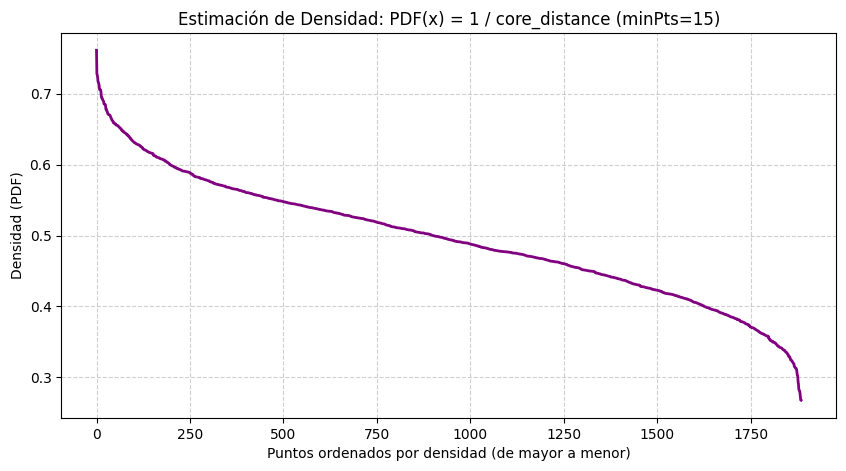

In [189]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Definimos el hiperparámetro k (minPts)
minPts = 15

# Calculamos las distancias a los k vecinos más cercanos
neighbors = NearestNeighbors(n_neighbors=minPts)
neighbors_fit = neighbors.fit(X_kmeans)
distances, indices = neighbors_fit.kneighbors(X_kmeans)

# La core distance es la distancia al k-ésimo vecino
core_distances = distances[:, -1]

# Calculamos la pseudo-densidad PDF(x) = 1 / core(x)
# Añadimos 1e-10 para evitar divisiones por cero en caso de puntos idénticos
pdf = 1 / (core_distances + 1e-10)

# Ordenamos de mayor a menor densidad para graficar
pdf_sorted = np.sort(pdf)[::-1]

plt.figure(figsize=(10, 5))
plt.plot(pdf_sorted, color='purple', linewidth=2)
plt.title(f'Estimación de Densidad: PDF(x) = 1 / core_distance (minPts={minPts})')
plt.xlabel('Puntos ordenados por densidad (de mayor a menor)')
plt.ylabel('Densidad (PDF)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Construcción del Modelo, Minimum Spanning Tree (MST) y Métrica DBCV

Se entrenó el algoritmo HDBSCAN con min_cluster_size=15, extrayendo el árbol de expansión mínima y evaluando el índice DBCV. Se observa que el modelo catalogó a la inmensa mayoría de las observaciones como ruido, aislando únicamente 2 micro-clústeres densos, lo que resulta en una validez DBCV muy baja debido a la continuidad espacial general de la muestra.

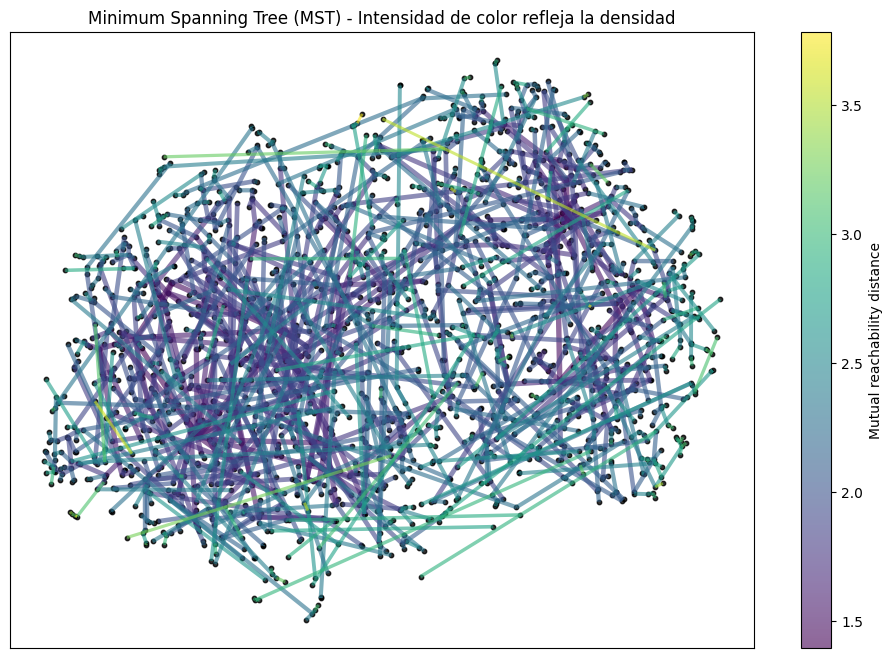

=== Resultados de HDBSCAN (Evaluación basada en Densidad) ===
Número de clústeres encontrados: 2
Cantidad de puntos clasificados como ruido: 1633

Métrica DBCV (Density-Based Clustering Validation): 0.0001


In [190]:
import hdbscan

# Entrenamos el modelo con la librería nativa para obtener DBCV y el MST
# gen_min_span_tree=True es obligatorio para extraer el grafo MST
hdb_model = hdbscan.HDBSCAN(min_cluster_size=minPts, min_samples=minPts, gen_min_span_tree=True, metric='euclidean')
labels = hdb_model.fit_predict(X_kmeans)

# Graficamos el Minimum Spanning Tree (MST)
plt.figure(figsize=(12, 8))
# edge_cmap define la paleta; colores más oscuros/intensos = mayor densidad (menor distancia)
hdb_model.minimum_spanning_tree_.plot(edge_cmap='viridis', edge_alpha=0.6, node_size=10, node_alpha=0.8)
plt.title('Minimum Spanning Tree (MST) - Intensidad de color refleja la densidad')
plt.show()

# Evaluación del modelo mediante DBCV (Relative Validity)
dbcv_score = hdb_model.relative_validity_
num_clusters = len(set(labels)) - (1 if -1 in labels else 0)
ruido = list(labels).count(-1)

print("=== Resultados de HDBSCAN (Evaluación basada en Densidad) ===")
print(f"Número de clústeres encontrados: {num_clusters}")
print(f"Cantidad de puntos clasificados como ruido: {ruido}")
print(f"\nMétrica DBCV (Density-Based Clustering Validation): {dbcv_score:.4f}")

### clusters generados por HDBSCAN

Se observa que el espacio está dominado por el ruido (etiqueta -1 en tonos oscuros), mientras que los clústeres 0 y 1 aparecen como pequeños núcleos localizados de manera aislada en los extremos de la distribución.

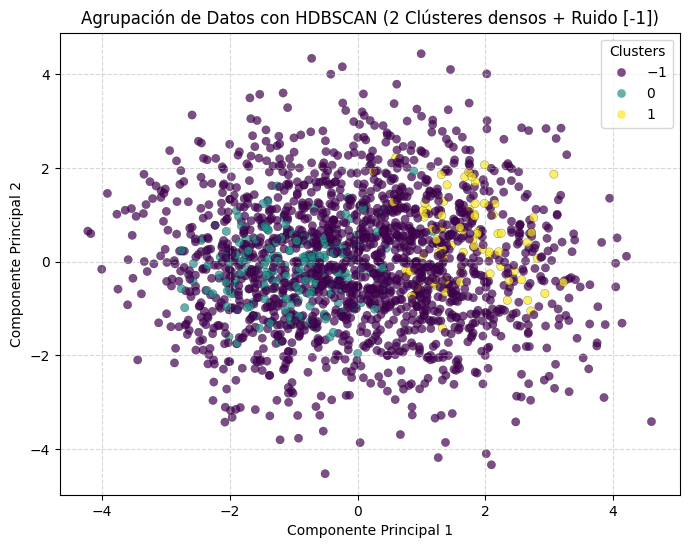

In [191]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 6))
scatter_hdb = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', alpha=0.7, edgecolors='k', linewidths=0.2)

plt.title('Agrupación de Datos con HDBSCAN (2 Clústeres densos + Ruido [-1])')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')

# Añadir leyenda
plt.legend(*scatter_hdb.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Caracterización Psicométrica y Sociodemográfica de los Clústeres

Se compararon las distribuciones psicométricas mediante diagramas de caja. Se observa que el grupo de ruido (-1) se alinea al promedio estándar (mediana en cero), mientras que los clústeres densos capturan perfiles opuestos y extremos: el clúster 1 representa el puntaje máximo en Búsqueda de Sensaciones (ss = 0.83) e impulsividad (0.56), y el clúster 0 representa el extremo opuesto con baja búsqueda de sensaciones (ss = -0.44) y alta Responsabilidad (cscore = 0.32).

/tmp/ipykernel_569/1379089005.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_569/1379089005.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_569/1379089005.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_569/1379089005.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_569/1379089005.py:20: FutureWarning: 

Passin

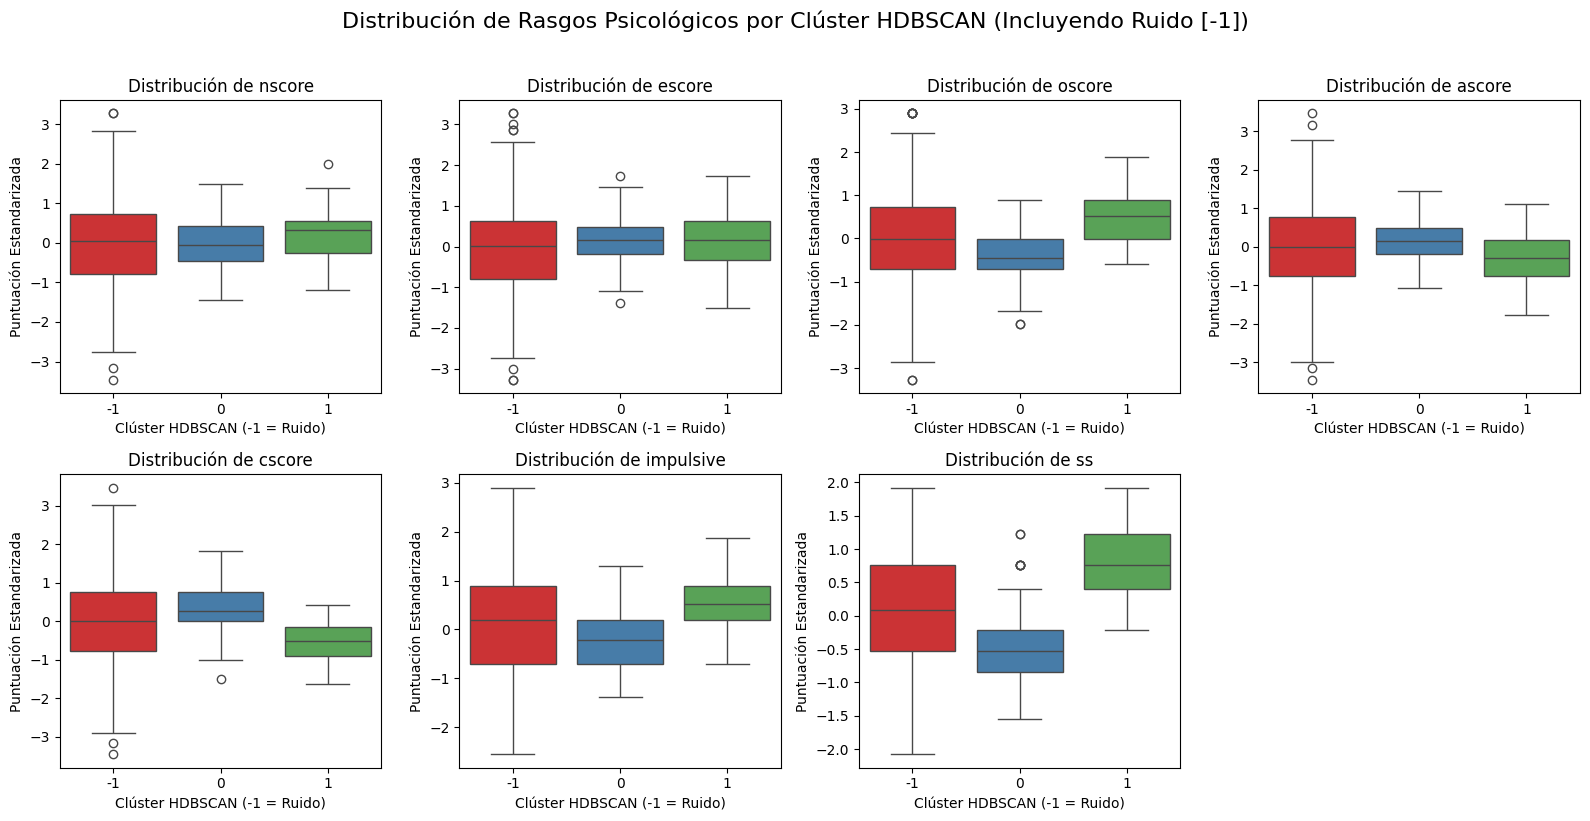

In [192]:
import matplotlib.pyplot as plt
import seaborn as sns

# Guardar las etiquetas de HDBSCAN en el dataframe principal
df01['cluster_hdbscan'] = labels

# Lista de variables psicológicas
variables_psicologicas = [
    'nscore', 'escore', 'oscore', 'ascore',
    'cscore', 'impulsive', 'ss'
]

# Configurar cuadrícula de subgráficos (2 filas x 4 columnas)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axes = axes.flatten()

# Iterar para generar cada boxplot usando las etiquetas de HDBSCAN
for i, var in enumerate(variables_psicologicas):
    # Mapeamos las etiquetas para que el gráfico sea más descriptivo
    sns.boxplot(
        x='cluster_hdbscan',
        y=var,
        data=df01,
        ax=axes[i],
        palette='Set1'
    )
    axes[i].set_title(f'Distribución de {var}')
    axes[i].set_xlabel('Clúster HDBSCAN (-1 = Ruido)')
    axes[i].set_ylabel('Puntuación Estandarizada')

# Ocultar el último eje vacío
axes[7].set_visible(False)

plt.suptitle('Distribución de Rasgos Psicológicos por Clúster HDBSCAN (Incluyendo Ruido [-1])', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### perfil promedio

Se analizaron las características promedio de los grupos. Se observa que la masa de ruido (-1) representa un perfil demográfico estándar (25-34 años), mientras que los clústeres aíslan nichos muy concretos: el clúster 0 concentra a mujeres maduras (35-44 años) de perfil conservador, y el clúster 1 agrupa a varones jóvenes (18-24 años) con alta impulsividad.

In [176]:
perfil_clusters_hdbscan = df01.groupby('cluster_hdbscan')[
    [
        'age',
        'gender',
        'education',
        'nscore',
        'escore',
        'oscore',
        'ascore',
        'cscore',
        'impulsive',
        'ss',
    ]
].mean()

# Desnormalizar las columnas sociodemográficas del perfil promedio para HDBSCAN
for col in ['age', 'gender', 'education']:
    perfil_clusters_hdbscan[col] = perfil_clusters_hdbscan[col].apply(lambda val: denormalize_uci_value(val, col))

print(perfil_clusters_hdbscan)

                   age     gender                                  education  \
cluster_hdbscan                                                                
-1               25-34  Masculino  Certificado / Diploma técnico profesional   
 0               35-44   Femenino             Grado universitario / Pregrado   
 1               18-24  Masculino     Algún curso universitario (sin título)   

                   nscore    escore    oscore    ascore    cscore  impulsive  \
cluster_hdbscan                                                                
-1              -0.003953 -0.024963  0.016140 -0.005696 -0.011575   0.025033   
 0              -0.063499  0.144561 -0.377714  0.162587  0.319886  -0.395975   
 1               0.233146  0.197574  0.514663 -0.260196 -0.501657   0.558095   

                       ss  
cluster_hdbscan            
-1               0.005663  
 0              -0.444923  
 1               0.827036  


### Perfil y Distribución Sociodemográfica de los Clústeres

Se evaluaron las proporciones demográficas detalladas. El clúster 1 está compuesto en un 92.11% por varones de 18-24 años procedentes de Estados Unidos (78.95%), mientras que el clúster 0 está compuesto en un 96.02% por individuos del Reino Unido, con predominio femenino (77.27%) y altos niveles de escolaridad.

In [171]:
# 1. Crear una copia de trabajo para no alterar el DataFrame original (df01)
df02 = df01.copy()

# 2. Lista de variables sociodemográficas a desnormalizar
vars_demograficas = ['age', 'gender', 'education', 'country', 'ethnicity']

# 3. Aplicar la desnormalización sobre la copia df02
for col in vars_demograficas:
  if col in df02.columns:
    df02[col] = denormalize_series(df02[col], col)

# 4. Generar y mostrar la tabulación cruzada en porcentaje para cada variable
for col in vars_demograficas:
  if col in df02.columns:
    print(f'=== Distribución porcentual de {col.upper()} por Clúster ===')
    tabla_porcentajes = (
        pd.crosstab(df02['cluster_hdbscan'], df02[col], normalize='index') * 100
    )
    print(tabla_porcentajes.round(2))
    print('\n')

=== Distribución porcentual de AGE por Clúster ===
age              18-24  25-34  35-44  45-54  55-64  65+
cluster_hdbscan                                        
-1               34.05  25.41  18.31  15.43    5.7  1.1
 0                9.66  34.09  32.39  23.86    0.0  0.0
 1               92.11   7.89   0.00   0.00    0.0  0.0


=== Distribución porcentual de GENDER por Clúster ===
gender           Femenino  Masculino
cluster_hdbscan                     
-1                  48.99      51.01
 0                  77.27      22.73
 1                   7.89      92.11


=== Distribución porcentual de EDUCATION por Clúster ===
education        Algún curso universitario (sin título)  \
cluster_hdbscan                                           
-1                                                27.07   
 0                                                 2.27   
 1                                                78.95   

education        Certificado / Diploma técnico profesional  Doctorado  \


### Tabulaciones cruzadas

Se calcularon las tasas de consumo por sustancia para cada grupo. Se evidencia que el Clúster 1 presenta proporciones de consumo extremas en sustancias recreativas como Cannabis (98.68%), Éxtasis (84.21%) y Legal highs (84.21%), contrastando masivamente con la baja prevalencia del Clúster 0 y los valores intermedios del ruido.

In [172]:
# Lista de sustancias a evaluar (usamos las columnas binarizadas que definimos previamente)
sustancias_cols = cols

# DataFrame auxiliar con la asignación del clúster y las variables de consumo ya binarizadas
df_consumo = df01[sustancias_cols + ['cluster_hdbscan']].copy()

# Proporción (porcentaje) de consumidores por clúster
prevalencia_consumo = (
    df_consumo.groupby('cluster_hdbscan')[sustancias_cols].mean() * 100
).round(2)
print(prevalencia_consumo.T)  # Transpuesto para ver sustancias en las filas

cluster_hdbscan     -1      0       1
alcohol          98.29  97.16   98.68
amphet           49.48  27.27   69.74
amyl             31.48  30.68   15.79
benzos           48.25  27.84   63.16
caff             98.41  99.43  100.00
cannabis         79.30  57.95   98.68
choc             98.35  98.86   96.05
coke             46.60  24.43   56.58
crack            14.08   6.25   22.37
ecstasy          46.36  24.43   84.21
heroin           15.43   3.98   27.63
ketamine         21.25  13.07   32.89
legalh           42.80  15.91   84.21
lsd              43.97  22.73   76.32
meth             24.49   7.39   56.58
mushrooms        48.62  25.57   84.21
nicotine         77.65  66.48   94.74
semer             0.43   0.00    1.32
vsa              23.82   7.95   35.53


### Pruebas de hipótesis

Se aplicaron pruebas Chi-cuadrado para contrastar la independencia del consumo frente a los grupos de densidad. Los resultados confirman diferencias estadísticamente significativas ($p < 0.05$) para la gran mayoría de sustancias ilícitas y recreativas (como legal highs con $\chi^2 = 105.23$ y éxtasis con $\chi^2 = 77.74$), mientras que sustancias como chocolate, cafeína, semer y alcohol resultan estadísticamente independientes ($p > 0.05$).

In [173]:
from scipy.stats import chi2_contingency

resultados_hipotesis = []

for droga in sustancias_cols:
  # Crear la tabla de contingencia de frecuencias absolutas
  contingency_table = pd.crosstab(df_consumo['cluster_hdbscan'], df_consumo[droga])

  # Ejecutar prueba Chi-cuadrado
  chi2, p_val, dof, _ = chi2_contingency(contingency_table)

  resultados_hipotesis.append({
      'Sustancia': droga,
      'Chi2': round(chi2, 3),
      'p-value': round(p_val, 5),
      '(p < 0.05)': 'Sí' if p_val < 0.05 else 'No',
  })

df_hipotesis = pd.DataFrame(resultados_hipotesis).sort_values(
    by='Chi2', ascending=False
)
print(df_hipotesis.to_string(index=False))

Sustancia    Chi2  p-value (p < 0.05)
   legalh 105.229  0.00000         Sí
  ecstasy  77.736  0.00000         Sí
mushrooms  75.664  0.00000         Sí
     meth  70.656  0.00000         Sí
      lsd  64.385  0.00000         Sí
 cannabis  61.947  0.00000         Sí
   amphet  46.059  0.00000         Sí
     coke  35.899  0.00000         Sí
   benzos  34.935  0.00000         Sí
      vsa  29.986  0.00000         Sí
   heroin  26.704  0.00000         Sí
 nicotine  25.026  0.00000         Sí
    crack  13.307  0.00129         Sí
 ketamine  13.236  0.00134         Sí
     amyl   8.389  0.01508         Sí
     choc   2.656  0.26495         No
     caff   2.331  0.31181         No
    semer   2.180  0.33625         No
  alcohol   1.244  0.53679         No
